# TACO — Evaluation notebook

## TACO model

Self-contained scorer class — needs only numpy and pandas. Loaded from a JSON spec file.

In [3]:
from taco_model import TACOModel

TACO = TACOModel.load("data/taco/taco_model.json")
print(f"TACO model: {len(TACO.spec['surfaces'])} surfaces, bias={TACO.spec.get('bias', 0.0):.6f}")

TACO model: 5 surfaces, bias=-4.535558


TACO loaded: 5 surfaces, 2 unique profiles, 2018 parameters
  pose: {'SP': 1.0, 'GD': 2.0, 'SIG_G': 2.0, 'SIG_C': 2.6, 'SW': 0.0}

Top-level keys: ['format', 'label', 'alphabet', 'kappa', 'loops', 'surfaces', 'pose', 'bias', 'provenance']
Per-surface keys: ['name', 'loops', 'M', 'w9']

The JSON stores a separate M and w9 per surface entry (5 entries),
but surfaces in the same class share identical values.  Naively summing
every entry gives 2000 + 5×9 = 2045,
but only 2 profiles are unique: 2000 + 2×9 = 2018.

  cdr1a  M (20, 20)  M shared with: (unique)  w9 shared with: ['cdr2a', 'cdr1b', 'cdr2b']
  cdr2a  M (20, 20)  M shared with: (unique)  w9 shared with: ['cdr1a', 'cdr1b', 'cdr2b']
  cdr1b  M (20, 20)  M shared with: (unique)  w9 shared with: ['cdr1a', 'cdr2a', 'cdr2b']
  cdr2b  M (20, 20)  M shared with: (unique)  w9 shared with: ['cdr1a', 'cdr2a', 'cdr1b']
  cdr3   M (20, 20)  M shared with: (unique)  w9 shared with: (unique)



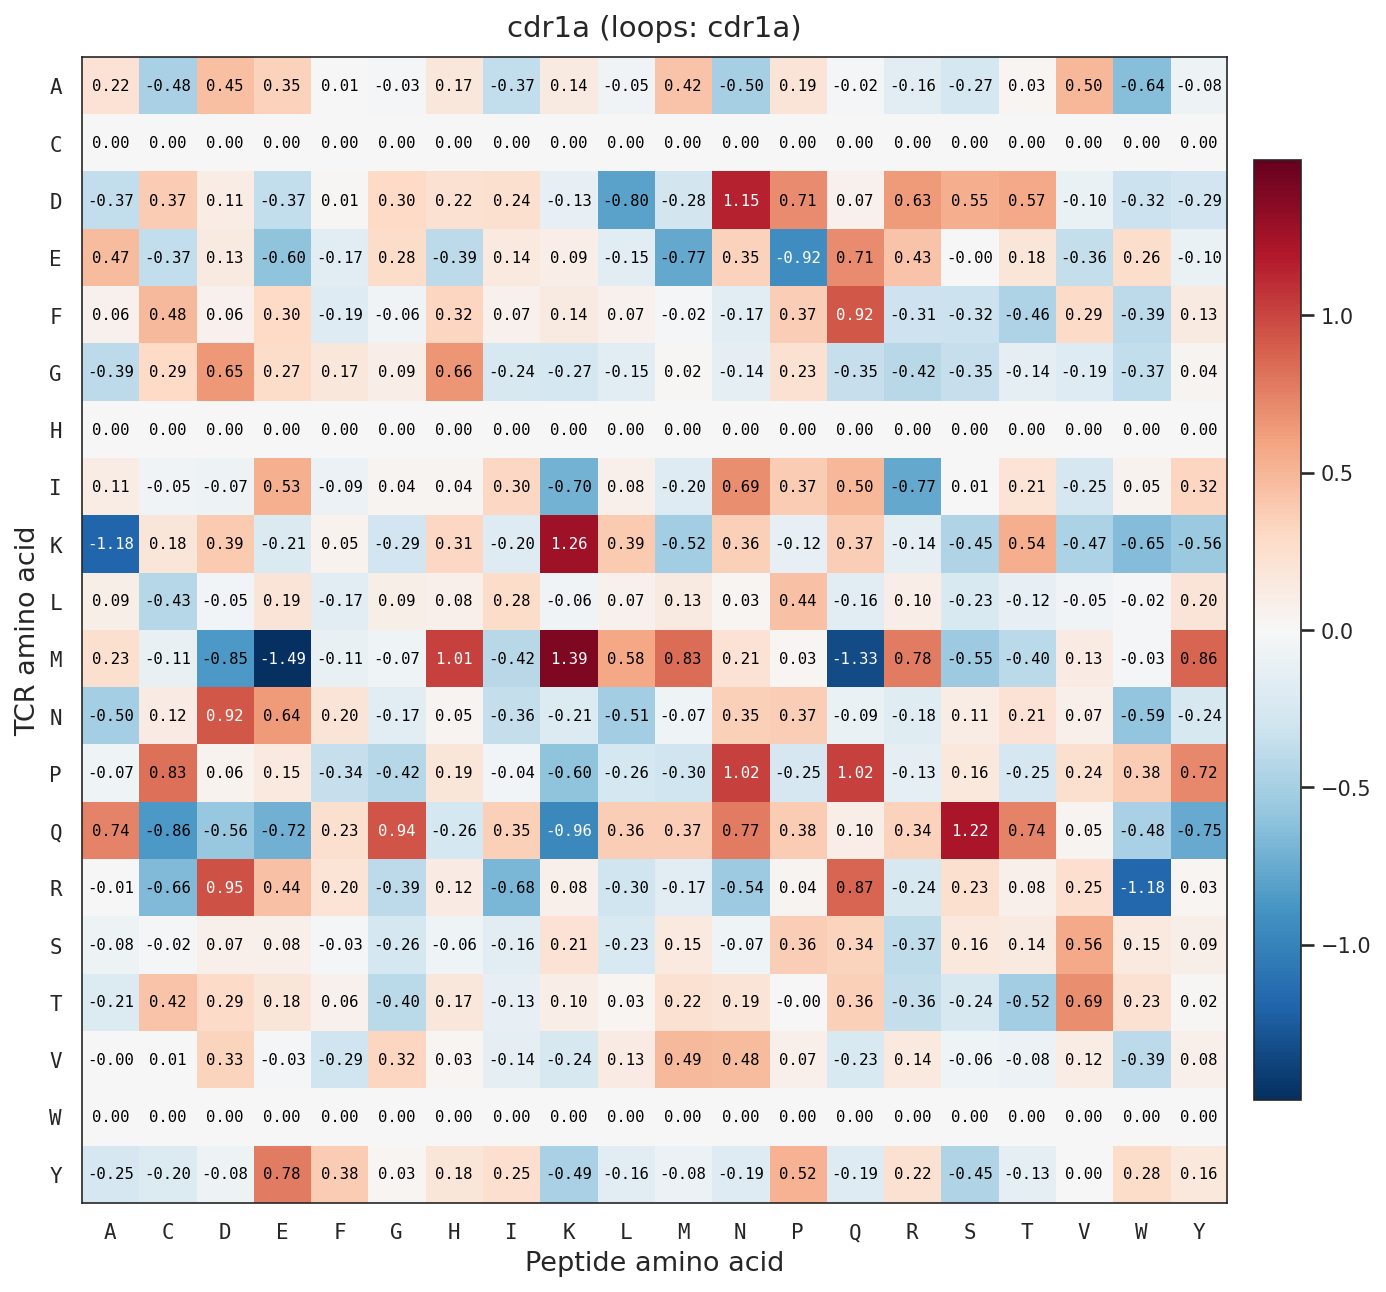

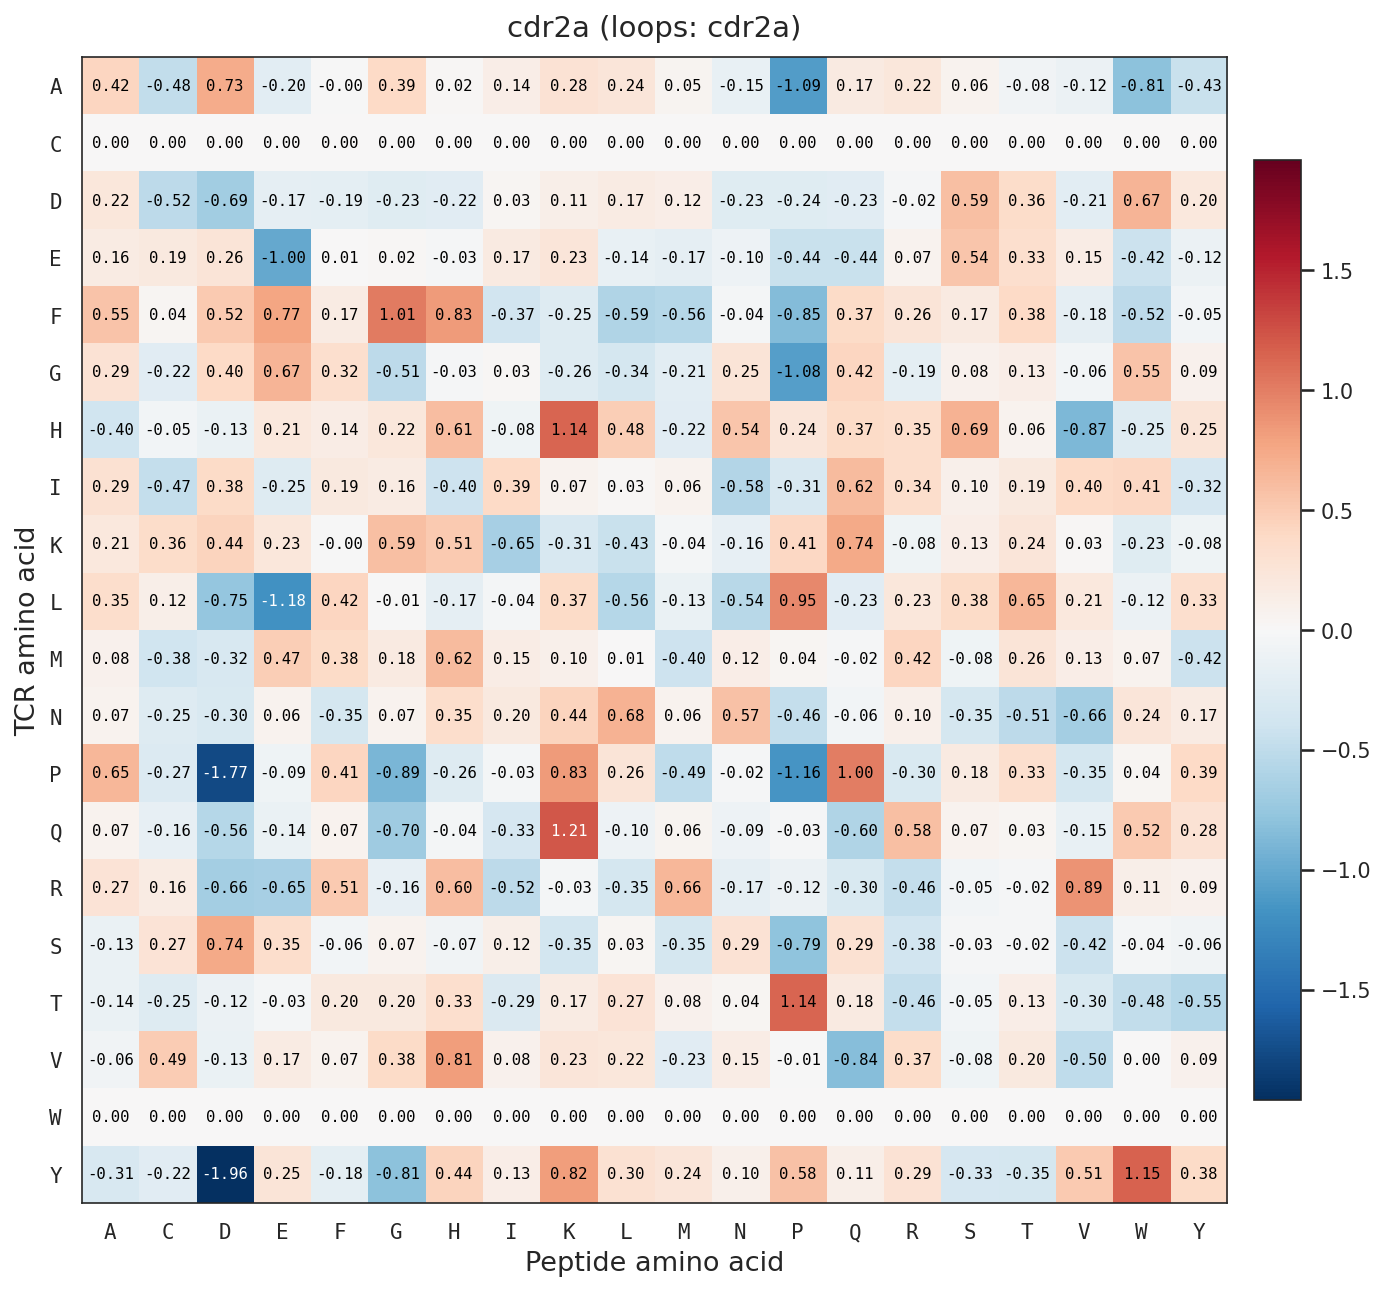

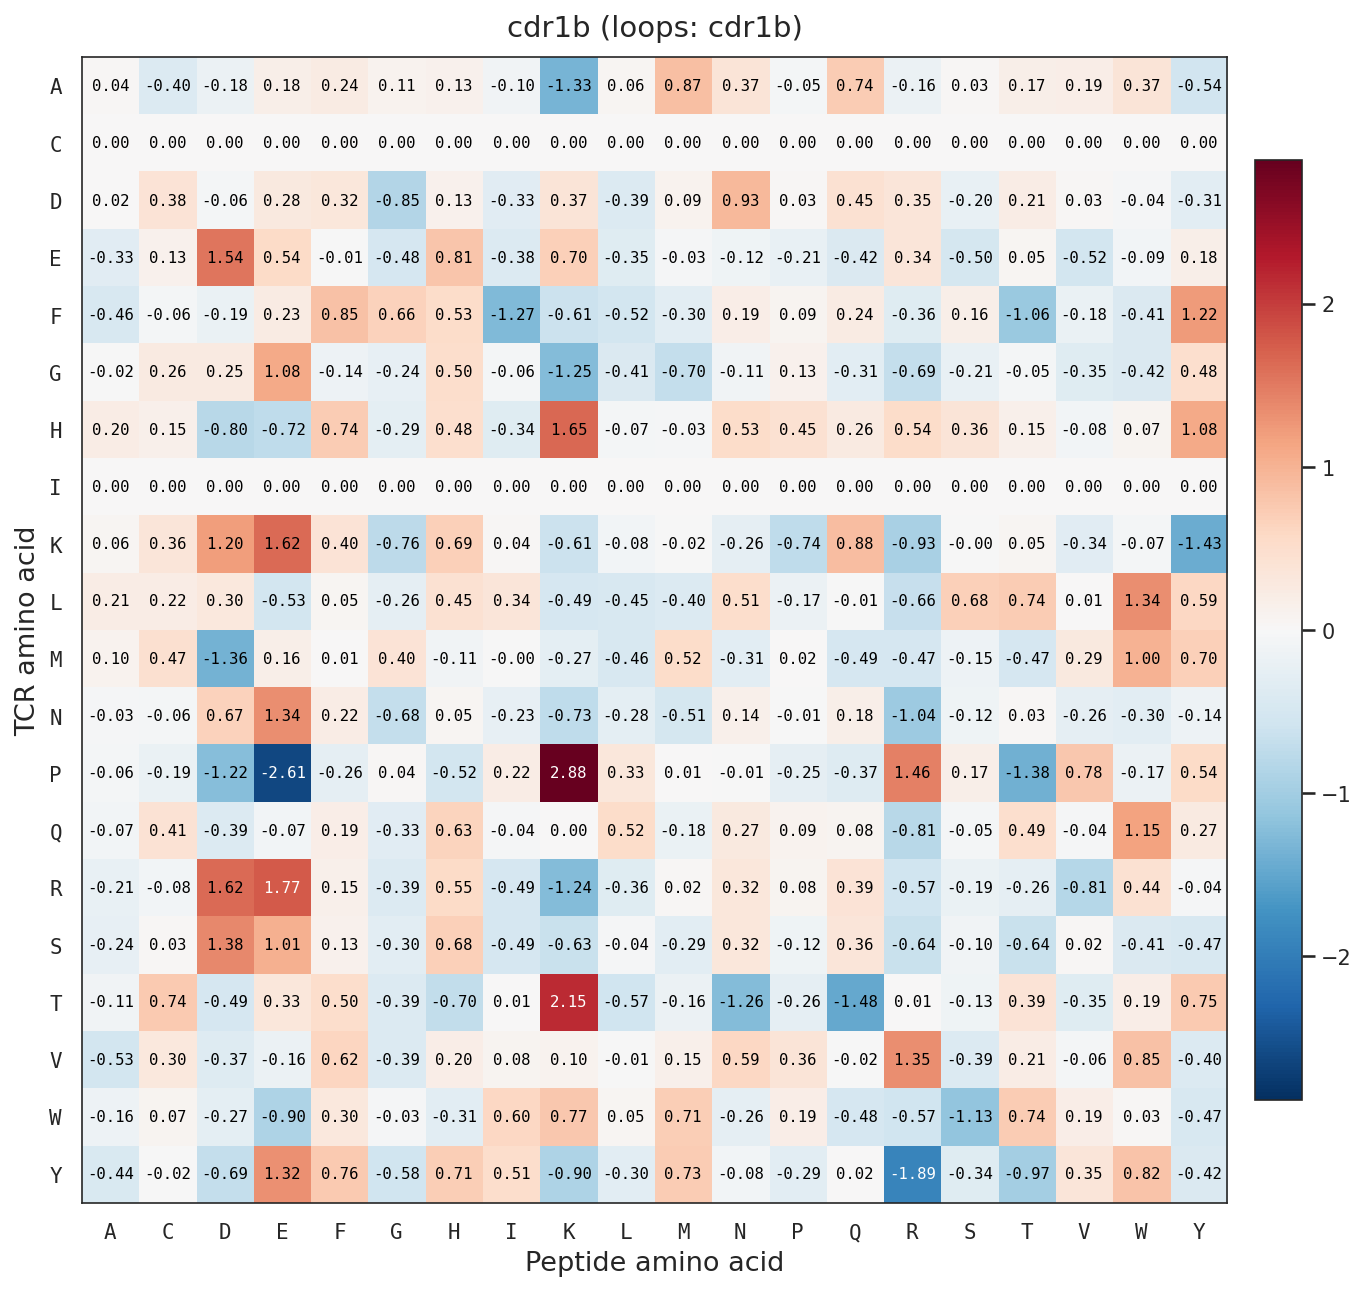

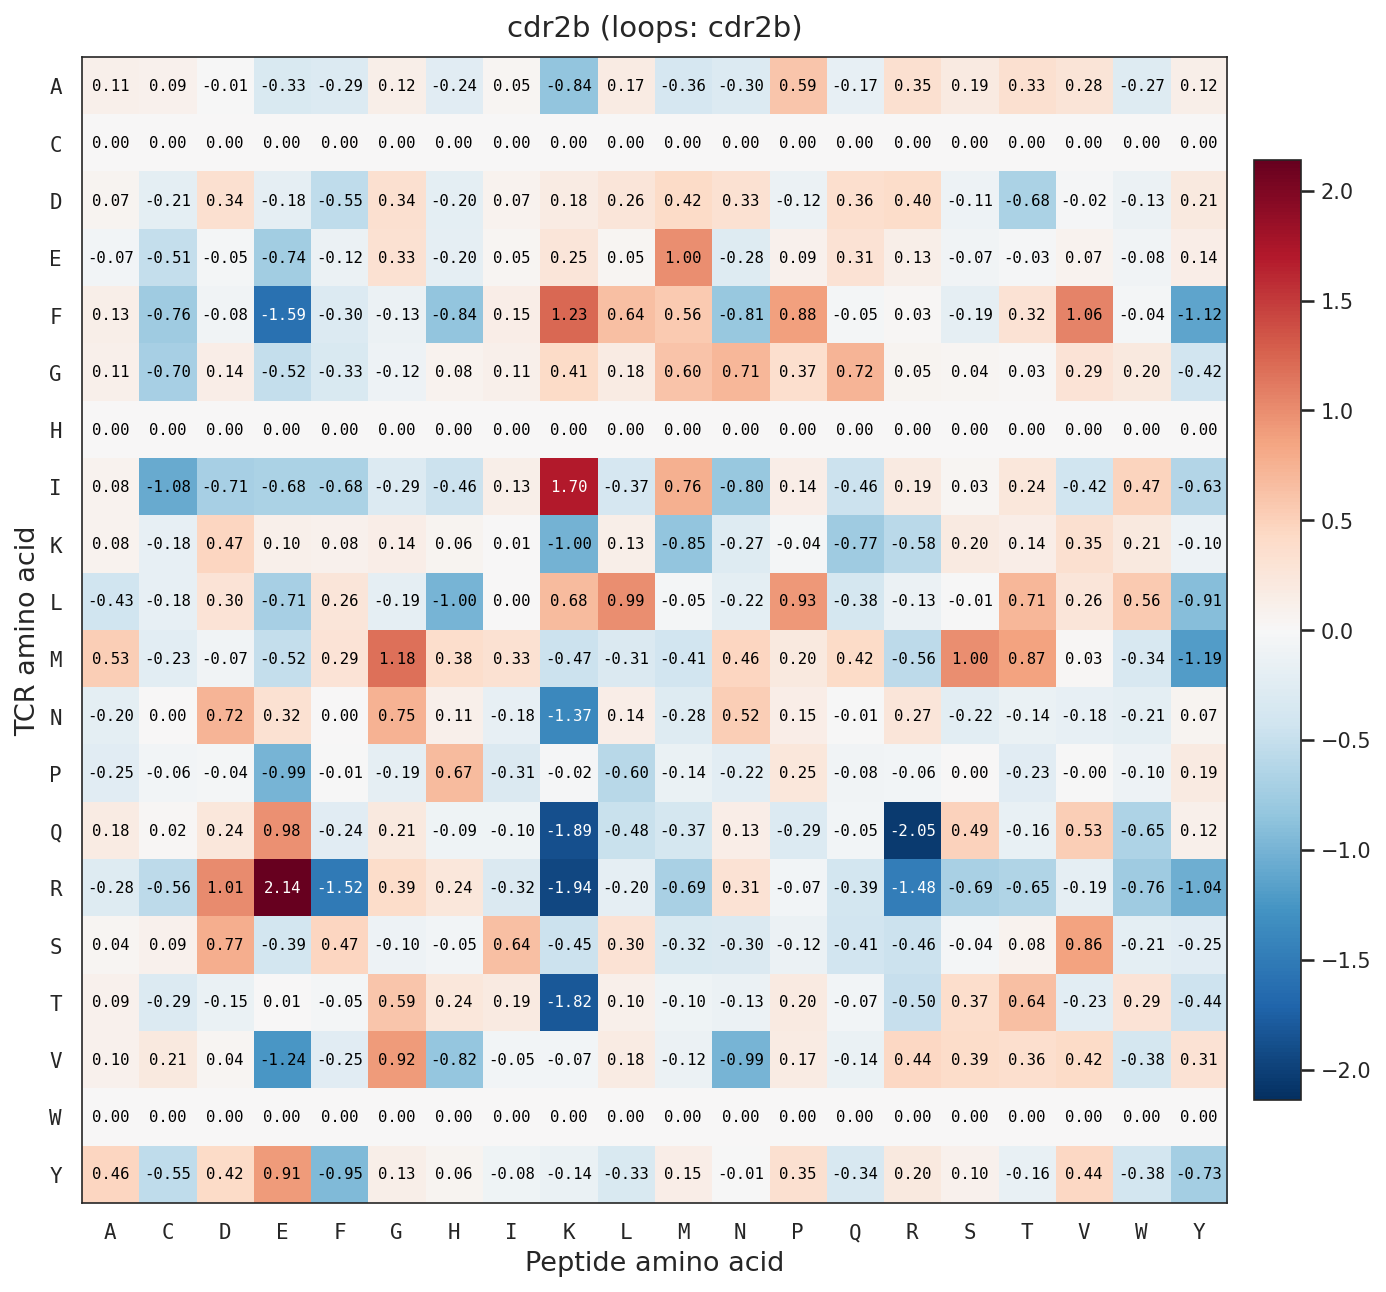

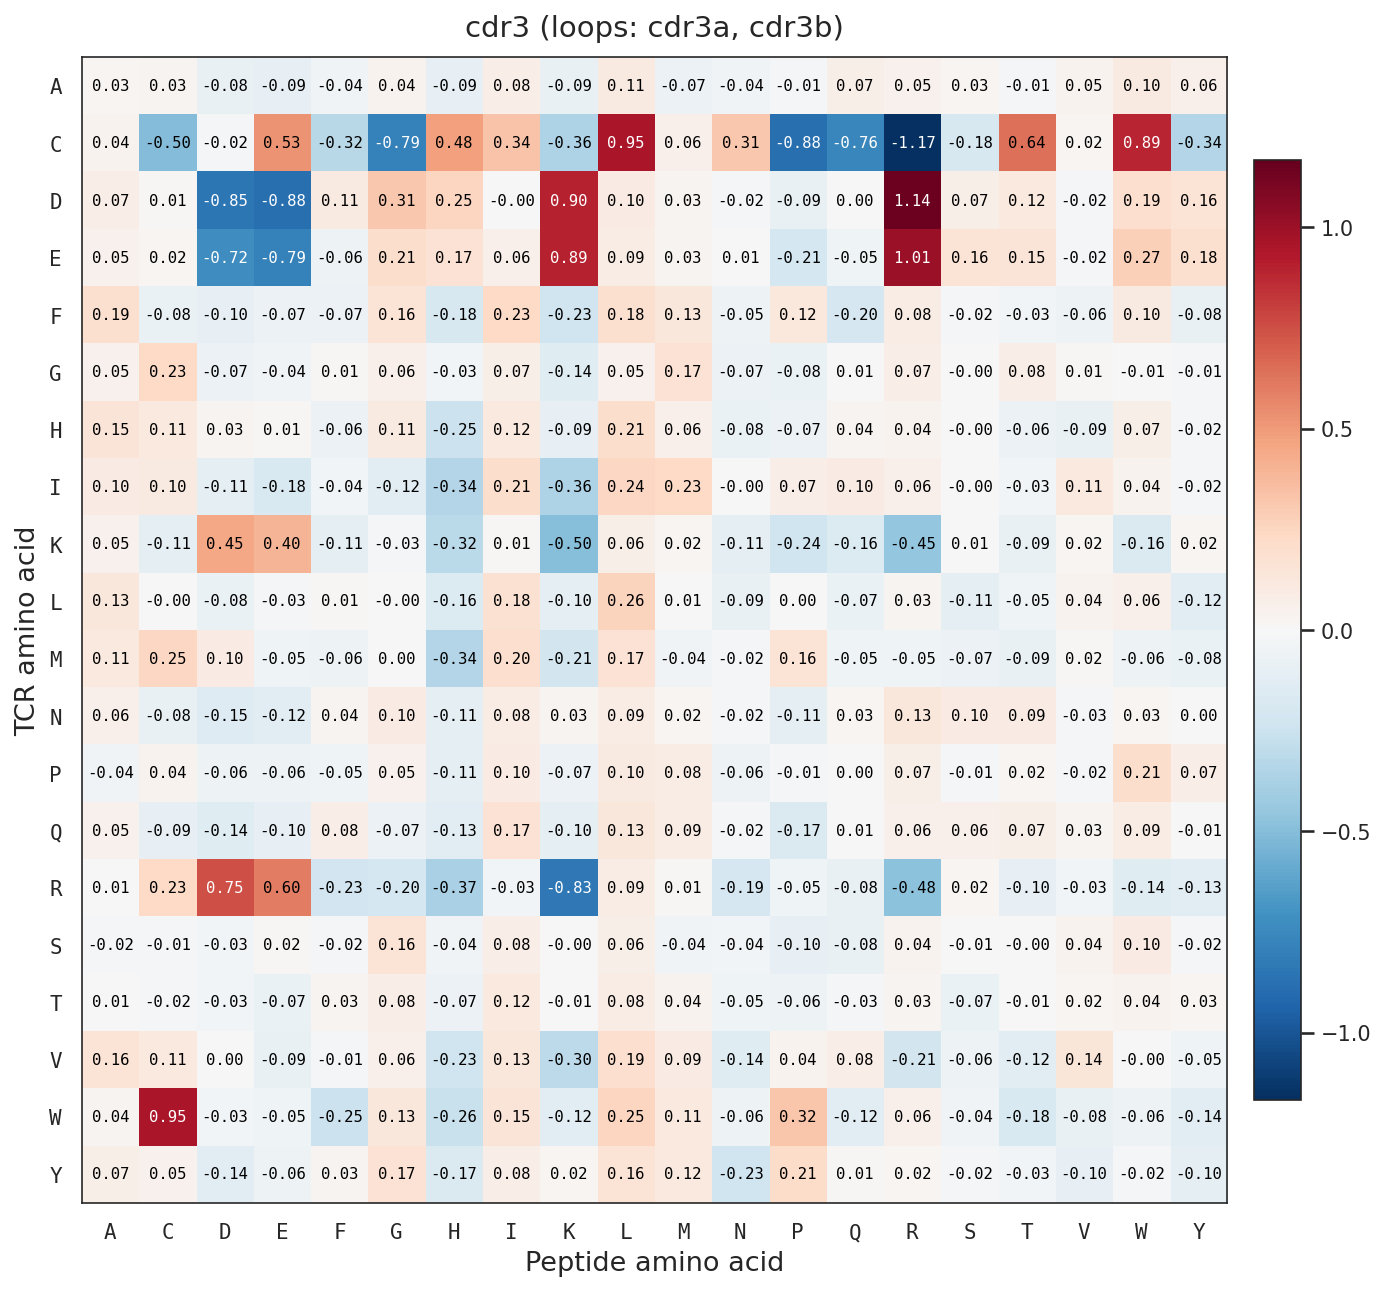

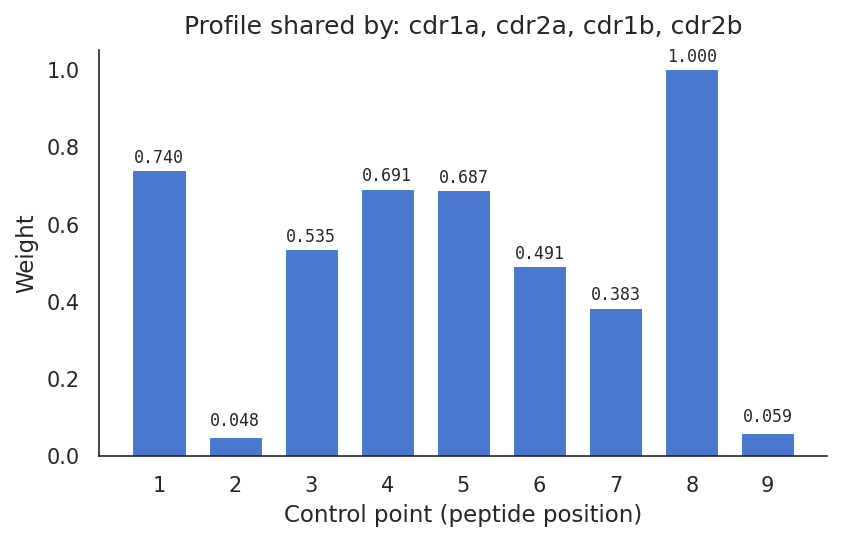

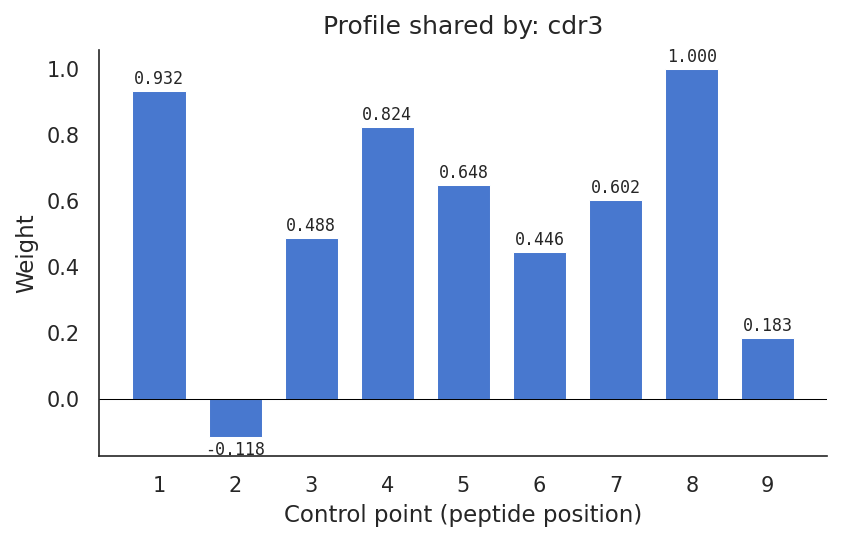

In [4]:
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# --- Journal-quality defaults ---
plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "font.size": 10,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        "legend.framealpha": 0.9,
        "font.family": "sans-serif",
        "axes.linewidth": 0.8,
        "grid.linewidth": 0.5,
        "lines.linewidth": 1.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

AA = TACO.spec["alphabet"]
n_surfaces = len(TACO.spec["surfaces"])
n_potentials = sum(np.array(s["M"]).size for s in TACO.spec["surfaces"])
_w9s = [tuple(s["w9"]) for s in TACO.spec["surfaces"]]
n_profiles = len(set(_w9s))
n_params = n_potentials + n_profiles * len(TACO.spec["surfaces"][0]["w9"])
print(f"TACO loaded: {n_surfaces} surfaces, {n_profiles} unique profiles, {n_params} parameters")
print(f"  pose: {TACO.spec['pose']}")
print()

# --- Spec structure ---
print("Top-level keys:", list(TACO.spec.keys()))
print("Per-surface keys:", list(TACO.spec["surfaces"][0].keys()))
print()

print(f"The JSON stores a separate M and w9 per surface entry ({n_surfaces} entries),")
print(f"but surfaces in the same class share identical values.  Naively summing")
print(f"every entry gives {n_potentials} + {n_surfaces}×9 = {n_potentials + n_surfaces * 9},")
print(f"but only {n_profiles} profiles are unique: {n_potentials} + {n_profiles}×9 = {n_params}.")
print()
for i, si in enumerate(TACO.spec["surfaces"]):
    Mi = np.array(si["M"])
    dupes = [
        sj["name"]
        for j, sj in enumerate(TACO.spec["surfaces"])
        if j != i and np.array_equal(np.array(sj["M"]), Mi)
    ]
    w9_dupes = [
        sj["name"]
        for j, sj in enumerate(TACO.spec["surfaces"])
        if j != i and tuple(sj["w9"]) == tuple(si["w9"])
    ]
    print(
        f"  {si['name']:<6} M {Mi.shape}  "
        f"M shared with: {dupes or '(unique)'}  "
        f"w9 shared with: {w9_dupes or '(unique)'}"
    )
print()

# --- Contact potentials (M matrices) — one heatmap per surface ---
_alpha_order = np.argsort(list(AA))
_alpha_labels = [AA[i] for i in _alpha_order]

for surf in TACO.spec["surfaces"]:
    M_raw = np.array(surf["M"], dtype=np.float32)
    M = M_raw[np.ix_(_alpha_order, _alpha_order)]
    vmax = np.abs(M).max()
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    fig, ax = plt.subplots(figsize=(10, 8.5), constrained_layout=True)
    im = ax.imshow(M, cmap="RdBu_r", norm=norm, aspect="equal")
    ax.set_xticks(range(20))
    ax.set_xticklabels(_alpha_labels, fontsize=10, fontfamily="monospace")
    ax.set_yticks(range(20))
    ax.set_yticklabels(_alpha_labels, fontsize=10, fontfamily="monospace")
    ax.set_xlabel("Peptide amino acid", fontsize=13)
    ax.set_ylabel("TCR amino acid", fontsize=13)
    loops_str = ", ".join(surf["loops"])
    ax.set_title(f"{surf['name']} (loops: {loops_str})", fontsize=14, pad=10)
    for i in range(20):
        for j in range(20):
            v = M[i, j]
            color = "white" if abs(v) > vmax * 0.6 else "black"
            ax.text(
                j,
                i,
                f"{v:.2f}",
                ha="center",
                va="center",
                fontsize=7.5,
                color=color,
                fontfamily="monospace",
            )
    ax.spines[:].set_visible(True)
    plt.colorbar(im, ax=ax, shrink=0.82, pad=0.02)
    plt.show()

# --- Exposure profiles (w9) ---
seen = set()
unique_profiles = []
for surf in TACO.spec["surfaces"]:
    key = tuple(surf["w9"])
    if key not in seen:
        seen.add(key)
        unique_profiles.append(surf)

for surf in unique_profiles:
    w9 = np.array(surf["w9"])
    sharing = [s["name"] for s in TACO.spec["surfaces"] if tuple(s["w9"]) == tuple(w9)]
    fig, ax = plt.subplots(figsize=(5.5, 3.5), constrained_layout=True)
    ax.bar(range(1, 10), w9, color="#4878CF", width=0.7, edgecolor="white", linewidth=0.5)
    ax.set_xticks(range(1, 10))
    ax.set_xlabel("Control point (peptide position)", fontsize=11)
    ax.set_ylabel("Weight", fontsize=11)
    ax.set_title(f"Profile shared by: {', '.join(sharing)}", fontsize=12, pad=8)
    ax.axhline(0, color="black", linewidth=0.5)
    for i, v in enumerate(w9):
        offset = 0.02 if abs(v) < 0.1 else 0.01
        ax.text(
            i + 1,
            v + offset * np.sign(v),
            f"{v:.3f}",
            ha="center",
            va="bottom" if v >= 0 else "top",
            fontsize=8,
            fontfamily="monospace",
        )
    plt.show()

### Physicochemical interpretation of learned contact potentials

The five contact potentials (M matrices) were learned purely from activation data.
We ask how much of the learned structure can be explained by known physicochemical
properties: BLOSUM substitution scores, Atchley factors, Kyte–Doolittle
hydrophobicity, and charge complementarity.

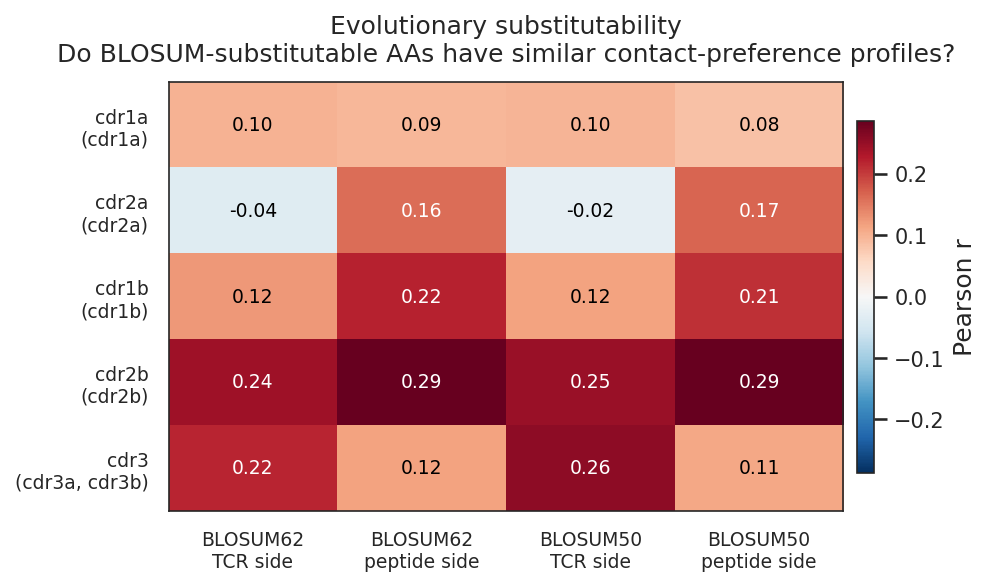

Interpretation: positive r means AAs that are evolutionarily
exchangeable also behave similarly in the learned potential.

  cdr1a   strongest: BLOSUM62 TCR side          r = +0.101
  cdr2a   strongest: BLOSUM50 peptide side      r = +0.168
  cdr1b   strongest: BLOSUM62 peptide side      r = +0.221
  cdr2b   strongest: BLOSUM50 peptide side      r = +0.287
  cdr3    strongest: BLOSUM50 TCR side          r = +0.257


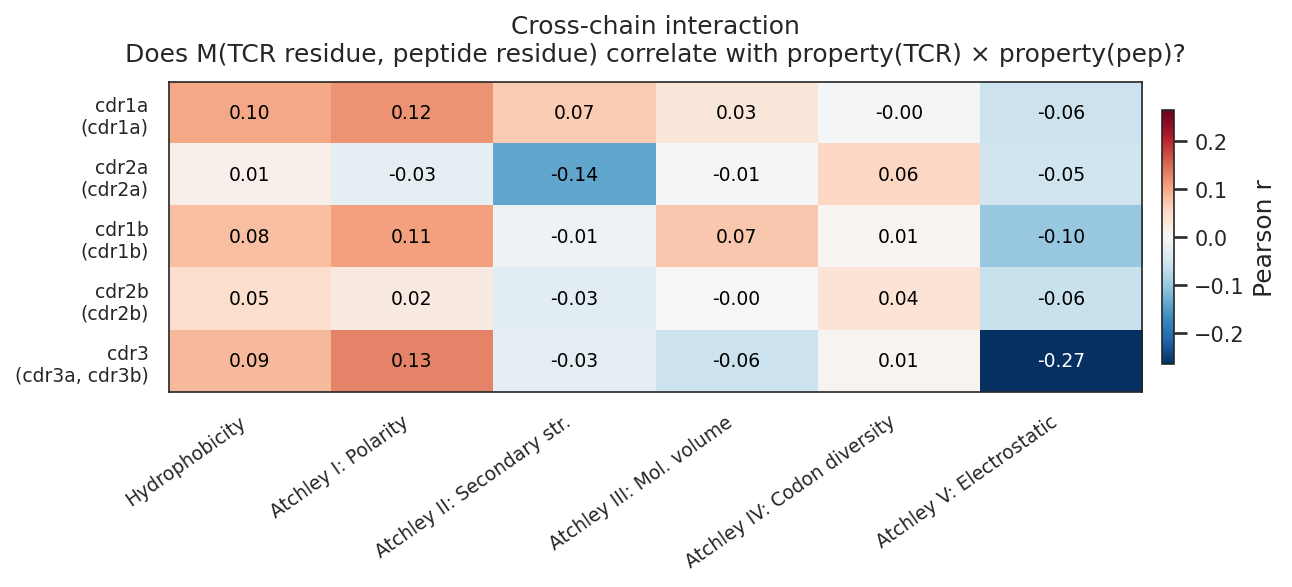

Interpretation: positive r means the potential favours contacts
between AAs that share high (or both low) values of that property.
Negative r means it favours complementary contacts (high × low).

  cdr1a   strongest: Atchley I: Polarity           r = +0.120
  cdr2a   strongest: Atchley II: Secondary str.    r = -0.137
  cdr1b   strongest: Atchley I: Polarity           r = +0.108
  cdr2b   strongest: Atchley V: Electrostatic      r = -0.059
  cdr3    strongest: Atchley V: Electrostatic      r = -0.265


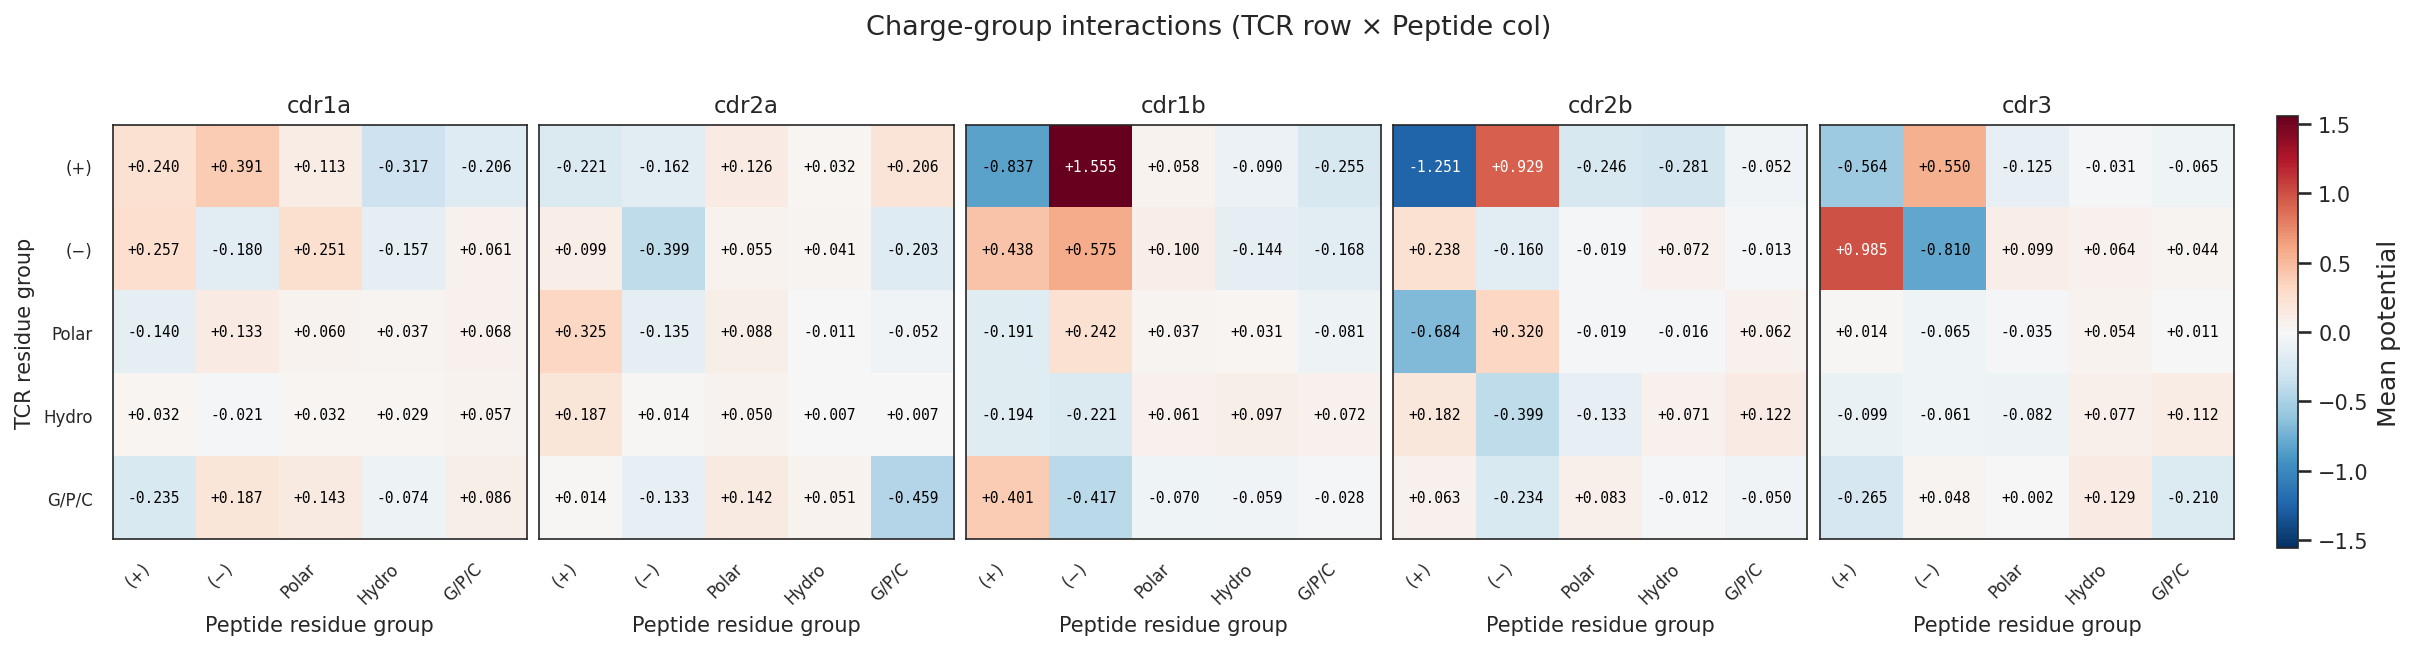


Charge complementarity check (mean potential):
  Surface   (+)×(−)    (+)×(+)    (−)×(−)  Complementary?
  cdr1a     +0.3910    +0.2396    -0.1803     no
  cdr2a     -0.1620    -0.2212    -0.3989     no
  cdr1b     +1.5553    -0.8374    +0.5748     no
  cdr2b     +0.9291    -1.2507    -0.1596     YES
  cdr3      +0.5503    -0.5636    -0.8096     YES


In [5]:
# --- Physicochemical decomposition of contact potentials ---

# Kyte-Doolittle hydrophobicity
KD_HYDRO = {
    "A": 1.8,
    "R": -4.5,
    "N": -3.5,
    "D": -3.5,
    "C": 2.5,
    "E": -3.5,
    "Q": -3.5,
    "G": -0.4,
    "H": -3.2,
    "I": 4.5,
    "L": 3.8,
    "K": -3.9,
    "M": 1.9,
    "F": 2.8,
    "P": -1.6,
    "S": -0.8,
    "T": -0.7,
    "W": -0.9,
    "Y": -1.3,
    "V": 4.2,
}

# Atchley factors (5 per amino acid)
ATCHLEY = {
    "A": [-0.591, -1.302, -0.733, 1.570, -0.146],
    "C": [-1.343, 0.465, -0.862, -1.020, -0.255],
    "D": [1.050, 0.302, -3.656, -0.259, -3.242],
    "E": [1.357, -1.453, 1.477, 0.113, -0.837],
    "F": [-1.006, -0.590, 1.891, -0.397, 0.412],
    "G": [-0.384, 1.652, 1.330, 1.045, 2.064],
    "H": [0.336, -0.417, -1.673, -1.474, -0.078],
    "I": [-1.239, -0.547, 2.131, 0.393, 0.816],
    "K": [1.831, -0.561, 0.533, -0.277, 1.648],
    "L": [-1.019, -0.987, -1.505, 1.266, -0.912],
    "M": [-0.663, -1.524, 2.219, -1.005, 1.212],
    "N": [0.945, 0.828, 1.299, -0.169, 0.933],
    "P": [0.189, 2.081, -1.628, 0.421, -1.392],
    "Q": [0.931, -0.179, -3.005, -0.503, -1.853],
    "R": [1.538, -0.055, 1.502, 0.440, 2.897],
    "S": [-0.228, 1.399, -4.760, 0.670, -2.647],
    "T": [-0.032, 0.326, 2.213, 0.908, 1.313],
    "V": [-1.337, -0.279, -0.544, 1.242, -1.262],
    "W": [-0.595, 0.009, 0.672, -2.128, -0.184],
    "Y": [0.260, 0.830, 3.097, -0.838, 1.512],
}
ATCHLEY_NAMES = [
    "I: Polarity",
    "II: Secondary str.",
    "III: Mol. volume",
    "IV: Codon diversity",
    "V: Electrostatic",
]

# BLOSUM62 and BLOSUM50 — standard ARNDCQEGHILKMFPSTWYV ordering
_BL_AA = "ARNDCQEGHILKMFPSTWYV"
_BLOSUM62_RAW = np.array(
    [
        [4, -1, -2, -2, 0, -1, -1, 0, -2, -1, -1, -1, -1, -2, -1, 1, 0, -3, -2, 0],
        [-1, 5, 0, -2, -3, 1, 0, -2, 0, -3, -2, 2, -1, -3, -2, -1, -1, -3, -2, -3],
        [-2, 0, 6, 1, -3, 0, 0, 0, 1, -3, -3, 0, -2, -3, -2, 1, 0, -4, -2, -3],
        [-2, -2, 1, 6, -3, 0, 2, -1, -1, -3, -4, -1, -3, -3, -1, 0, -1, -4, -3, -3],
        [0, -3, -3, -3, 9, -3, -4, -3, -3, -1, -1, -3, -1, -2, -3, -1, -1, -2, -2, -1],
        [-1, 1, 0, 0, -3, 5, 2, -2, 0, -3, -2, 1, 0, -3, -1, 0, -1, -2, -1, -2],
        [-1, 0, 0, 2, -4, 2, 5, -2, 0, -3, -3, 1, -2, -3, -1, 0, -1, -3, -2, -2],
        [0, -2, 0, -1, -3, -2, -2, 6, -2, -4, -4, -2, -3, -3, -2, 0, -2, -2, -3, -3],
        [-2, 0, 1, -1, -3, 0, 0, -2, 8, -3, -3, -1, -2, -1, -2, -1, -2, -2, 2, -3],
        [-1, -3, -3, -3, -1, -3, -3, -4, -3, 4, 2, -3, 1, 0, -3, -2, -1, -3, -1, 3],
        [-1, -2, -3, -4, -1, -2, -3, -4, -3, 2, 4, -2, 2, 0, -3, -2, -1, -2, -1, 1],
        [-1, 2, 0, -1, -3, 1, 1, -2, -1, -3, -2, 5, -1, -3, -1, 0, -1, -3, -2, -2],
        [-1, -1, -2, -3, -1, 0, -2, -3, -2, 1, 2, -1, 5, 0, -2, -1, -1, -1, -1, 1],
        [-2, -3, -3, -3, -2, -3, -3, -3, -1, 0, 0, -3, 0, 6, -4, -2, -2, 1, 3, -1],
        [-1, -2, -2, -1, -3, -1, -1, -2, -2, -3, -3, -1, -2, -4, 7, -1, -1, -4, -3, -2],
        [1, -1, 1, 0, -1, 0, 0, 0, -1, -2, -2, 0, -1, -2, -1, 4, 1, -3, -2, -2],
        [0, -1, 0, -1, -1, -1, -1, -2, -2, -1, -1, -1, -1, -2, -1, 1, 5, -2, -2, 0],
        [-3, -3, -4, -4, -2, -2, -3, -2, -2, -3, -2, -3, -1, 1, -4, -3, -2, 11, 2, -3],
        [-2, -2, -2, -3, -2, -1, -2, -3, 2, -1, -1, -2, -1, 3, -3, -2, -2, 2, 7, -1],
        [0, -3, -3, -3, -1, -2, -2, -3, -3, 3, 1, -2, 1, -1, -2, -2, 0, -3, -1, 4],
    ],
    dtype=float,
)

_BLOSUM50_RAW = np.array(
    [
        [5, -2, -1, -2, -1, -1, -1, 0, -2, -1, -2, -1, -1, -3, -1, 1, 0, -3, -2, 0],
        [-2, 7, -1, -2, -4, 1, 0, -3, 0, -4, -3, 3, -2, -3, -3, -1, -1, -3, -1, -3],
        [-1, -1, 7, 2, -2, 0, 0, 0, 1, -3, -4, 0, -2, -4, -2, 1, 0, -4, -2, -3],
        [-2, -2, 2, 8, -4, 0, 2, -1, -1, -4, -4, -1, -4, -5, -1, 0, -1, -5, -3, -4],
        [-1, -4, -2, -4, 13, -3, -3, -3, -3, -2, -2, -3, -2, -2, -4, -1, -1, -5, -3, -1],
        [-1, 1, 0, 0, -3, 7, 2, -2, 1, -3, -2, 2, 0, -4, -1, 0, -1, -1, -1, -3],
        [-1, 0, 0, 2, -3, 2, 6, -3, 0, -4, -3, 1, -2, -3, -1, -1, -1, -3, -2, -3],
        [0, -3, 0, -1, -3, -2, -3, 8, -2, -4, -4, -2, -3, -4, -2, 0, -2, -3, -3, -4],
        [-2, 0, 1, -1, -3, 1, 0, -2, 10, -4, -3, 0, -1, -1, -2, -1, -2, -3, 2, -4],
        [-1, -4, -3, -4, -2, -3, -4, -4, -4, 5, 2, -3, 2, 0, -3, -3, -1, -3, -1, 4],
        [-2, -3, -4, -4, -2, -2, -3, -4, -3, 2, 5, -3, 3, 1, -4, -3, -1, -2, -1, 1],
        [-1, 3, 0, -1, -3, 2, 1, -2, 0, -3, -3, 6, -2, -4, -1, 0, -1, -3, -2, -3],
        [-1, -2, -2, -4, -2, 0, -2, -3, -1, 2, 3, -2, 7, 0, -3, -2, -1, -1, 0, 1],
        [-3, -3, -4, -5, -2, -4, -3, -4, -1, 0, 1, -4, 0, 8, -4, -3, -2, 1, 4, -1],
        [-1, -3, -2, -1, -4, -1, -1, -2, -2, -3, -4, -1, -3, -4, 10, -1, -1, -4, -3, -3],
        [1, -1, 1, 0, -1, 0, -1, 0, -1, -3, -3, 0, -2, -3, -1, 5, 2, -4, -2, -2],
        [0, -1, 0, -1, -1, -1, -1, -2, -2, -1, -1, -1, -1, -2, -1, 2, 5, -3, -2, 0],
        [-3, -3, -4, -5, -5, -1, -3, -3, -3, -3, -2, -3, -1, 1, -4, -4, -3, 15, 2, -3],
        [-2, -1, -2, -3, -3, -1, -2, -3, 2, -1, -1, -2, 0, 4, -3, -2, -2, 2, 8, -1],
        [0, -3, -3, -4, -1, -3, -3, -4, -4, 4, 1, -3, 1, -1, -3, -2, 0, -3, -1, 5],
    ],
    dtype=float,
)

# Reorder to match TACO alphabet
alpha = TACO.spec["alphabet"]
n_aa = len(alpha)
_bl_idx = {aa: i for i, aa in enumerate(_BL_AA)}
_reorder = [_bl_idx[aa] for aa in alpha]
blosum62 = _BLOSUM62_RAW[np.ix_(_reorder, _reorder)]
blosum50 = _BLOSUM50_RAW[np.ix_(_reorder, _reorder)]

# Atchley & hydrophobicity vectors in TACO alphabet order
atchley_vecs = np.array([ATCHLEY[aa] for aa in alpha])  # (20, 5)
hydro = np.array([KD_HYDRO[aa] for aa in alpha])


def flat_corr(a, b):
    return np.corrcoef(a, b)[0, 1]


# ══════════════════════════════════════════════════════════════
# Figure 1 — Evolutionary substitutability (BLOSUM)
# ══════════════════════════════════════════════════════════════
# BLOSUM measures how often one AA substitutes for another in the
# *same chain*. The right question is: do substitutable AAs have
# similar contact-preference profiles when they appear on the TCR
# side (row cosine similarity) or peptide side (column similarity)?


def _pairwise_cos_sim(M, axis):
    """Cosine similarity between all row (axis=0) or column (axis=1) pairs."""
    if axis == 1:
        M = M.T
    norms = np.linalg.norm(M, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    S = (M / norms) @ (M / norms).T
    return S[np.triu_indices(S.shape[0], k=1)]


blosum62_ut = blosum62[np.triu_indices(n_aa, k=1)]
blosum50_ut = blosum50[np.triu_indices(n_aa, k=1)]

surf_labels = []
bl_corr = np.zeros((len(TACO.spec["surfaces"]), 4))  # BL62-row, BL62-col, BL50-row, BL50-col
bl_col_labels = [
    "BLOSUM62\nTCR side",
    "BLOSUM62\npeptide side",
    "BLOSUM50\nTCR side",
    "BLOSUM50\npeptide side",
]

for si, surf in enumerate(TACO.spec["surfaces"]):
    M = np.array(surf["M"], dtype=float)
    loops_str = ", ".join(surf["loops"])
    surf_labels.append(f"{surf['name']}\n({loops_str})")
    row_sim = _pairwise_cos_sim(M, axis=0)
    col_sim = _pairwise_cos_sim(M, axis=1)
    bl_corr[si, 0] = flat_corr(row_sim, blosum62_ut)
    bl_corr[si, 1] = flat_corr(col_sim, blosum62_ut)
    bl_corr[si, 2] = flat_corr(row_sim, blosum50_ut)
    bl_corr[si, 3] = flat_corr(col_sim, blosum50_ut)

fig, ax = plt.subplots(figsize=(6.5, 3.8), constrained_layout=True)
vmax = np.abs(bl_corr).max()
im = ax.imshow(bl_corr, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(4))
ax.set_xticklabels(bl_col_labels, fontsize=9, ha="center")
ax.set_yticks(range(len(surf_labels)))
ax.set_yticklabels(surf_labels, fontsize=9)
for i in range(bl_corr.shape[0]):
    for j in range(bl_corr.shape[1]):
        v = bl_corr[i, j]
        color = "white" if abs(v) > vmax * 0.55 else "black"
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=color)
ax.set_title(
    "Evolutionary substitutability\n"
    "Do BLOSUM-substitutable AAs have similar contact-preference profiles?",
    fontsize=12,
    pad=10,
)
ax.spines[:].set_visible(True)
plt.colorbar(im, ax=ax, shrink=0.82, pad=0.02, label="Pearson r")
plt.show()

print("Interpretation: positive r means AAs that are evolutionarily")
print("exchangeable also behave similarly in the learned potential.")
print()
for si, surf in enumerate(TACO.spec["surfaces"]):
    best_j = np.argmax(np.abs(bl_corr[si]))
    lbl = bl_col_labels[best_j].replace("\n", " ")
    print(f"  {surf['name']:<6s}  strongest: {lbl:<25s}  r = {bl_corr[si, best_j]:+.3f}")

# ══════════════════════════════════════════════════════════════
# Figure 2 — Cross-chain physicochemical interactions
# ══════════════════════════════════════════════════════════════
# Atchley factors and hydrophobicity are properties of individual
# amino acids. The natural question for cross-chain potentials is:
# does M(i,j) correlate with property(i) × property(j)?
# A positive correlation means the potential favours contacts
# between AAs that share high/low values of that property.

xc_labels = ["Hydrophobicity"] + [f"Atchley {n}" for n in ATCHLEY_NAMES]
xc_corr = np.zeros((len(TACO.spec["surfaces"]), len(xc_labels)))

for si, surf in enumerate(TACO.spec["surfaces"]):
    M = np.array(surf["M"], dtype=float).ravel()
    xc_corr[si, 0] = flat_corr(M, np.outer(hydro, hydro).ravel())
    for k in range(5):
        v = atchley_vecs[:, k]
        xc_corr[si, k + 1] = flat_corr(M, np.outer(v, v).ravel())

fig, ax = plt.subplots(figsize=(8.5, 3.8), constrained_layout=True)
vmax2 = np.abs(xc_corr).max()
im = ax.imshow(xc_corr, cmap="RdBu_r", vmin=-vmax2, vmax=vmax2, aspect="auto")
ax.set_xticks(range(len(xc_labels)))
ax.set_xticklabels(xc_labels, fontsize=9, rotation=35, ha="right")
ax.set_yticks(range(len(surf_labels)))
ax.set_yticklabels(surf_labels, fontsize=9)
for i in range(xc_corr.shape[0]):
    for j in range(xc_corr.shape[1]):
        v = xc_corr[i, j]
        color = "white" if abs(v) > vmax2 * 0.55 else "black"
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=color)
ax.set_title(
    "Cross-chain interaction\n"
    "Does M(TCR residue, peptide residue) correlate with property(TCR) × property(pep)?",
    fontsize=12,
    pad=10,
)
ax.spines[:].set_visible(True)
plt.colorbar(im, ax=ax, shrink=0.82, pad=0.02, label="Pearson r")
plt.show()

print("Interpretation: positive r means the potential favours contacts")
print("between AAs that share high (or both low) values of that property.")
print("Negative r means it favours complementary contacts (high × low).")
print()
for si, surf in enumerate(TACO.spec["surfaces"]):
    best_j = np.argmax(np.abs(xc_corr[si]))
    print(
        f"  {surf['name']:<6s}  strongest: {xc_labels[best_j]:<28s}"
        f"  r = {xc_corr[si, best_j]:+.3f}"
    )

# ══════════════════════════════════════════════════════════════
# Figure 3 — Charge-group interactions
# ══════════════════════════════════════════════════════════════
charge_groups = {
    "Positive (K, R)": [i for i, aa in enumerate(alpha) if aa in "KR"],
    "Negative (D, E)": [i for i, aa in enumerate(alpha) if aa in "DE"],
    "Polar uncharged": [i for i, aa in enumerate(alpha) if aa in "NQHSTY"],
    "Hydrophobic": [i for i, aa in enumerate(alpha) if aa in "AVILMFW"],
    "Special (G, P, C)": [i for i, aa in enumerate(alpha) if aa in "GPC"],
}
grp_short = ["(+)", "(−)", "Polar", "Hydro", "G/P/C"]

n_surf = len(TACO.spec["surfaces"])
n_grp = len(charge_groups)
fig, axes = plt.subplots(1, n_surf, figsize=(3.2 * n_surf, 4.0), constrained_layout=True)

vabs_all = 0
grp_mats = []
for si, surf in enumerate(TACO.spec["surfaces"]):
    M = np.array(surf["M"], dtype=float)
    G = np.zeros((n_grp, n_grp))
    for gi, (_, idx_i) in enumerate(charge_groups.items()):
        for gj, (_, idx_j) in enumerate(charge_groups.items()):
            G[gi, gj] = M[np.ix_(idx_i, idx_j)].mean()
    grp_mats.append(G)
    vabs_all = max(vabs_all, np.abs(G).max())

for si, surf in enumerate(TACO.spec["surfaces"]):
    ax = axes[si]
    G = grp_mats[si]
    im = ax.imshow(G, cmap="RdBu_r", vmin=-vabs_all, vmax=vabs_all, aspect="equal")
    ax.set_xticks(range(n_grp))
    ax.set_xticklabels(grp_short, fontsize=8, rotation=45, ha="right")
    ax.set_yticks(range(n_grp))
    ax.set_yticklabels(grp_short if si == 0 else [], fontsize=8)
    if si == 0:
        ax.set_ylabel("TCR residue group", fontsize=10)
    ax.set_xlabel("Peptide residue group", fontsize=10)
    ax.set_title(surf["name"], fontsize=11, pad=6)
    for i in range(n_grp):
        for j in range(n_grp):
            v = G[i, j]
            color = "white" if abs(v) > vabs_all * 0.55 else "black"
            ax.text(
                j,
                i,
                f"{v:+.3f}",
                ha="center",
                va="center",
                fontsize=7,
                color=color,
                fontfamily="monospace",
            )
    ax.spines[:].set_visible(True)

fig.colorbar(im, ax=axes, shrink=0.75, pad=0.02, label="Mean potential")
fig.suptitle("Charge-group interactions (TCR row × Peptide col)", fontsize=13, y=1.04)
plt.show()

print("\nCharge complementarity check (mean potential):")
header_cols = "(+)×(−)    (+)×(+)    (−)×(−)"
print(f"  {'Surface':<8s}  {header_cols}  Complementary?")
for si, surf in enumerate(TACO.spec["surfaces"]):
    G = grp_mats[si]
    pn = G[0, 1]
    pp = G[0, 0]
    nn = G[1, 1]
    comp = "YES" if (pn > 0 and pp < 0 and nn < 0) or (pn < 0 and pp > 0 and nn > 0) else "no"
    print(f"  {surf['name']:<8s}  {pn:+.4f}    {pp:+.4f}    {nn:+.4f}     {comp}")

**Observations**

**1. CDR3 is the electrostatic surface.**
The cross-chain analysis picks up Atchley V (electrostatic) at
r = &minus;0.27 &mdash; the single strongest property correlation of any
surface. The raw matrix confirms this: D and E rows show clean
complementarity (D&times;K = +0.90, D&times;R = +1.14, D&times;D = &minus;0.85,
D&times;E = &minus;0.88; mirror pattern for E), and K/R rows follow suit.
Most other rows (A, F, G, I, L, M, N, P, S, T, V) are flat
&mdash; CDR3&rsquo;s signal is concentrated in just five residues
(C, D, E, K, R), with the rest near zero.
The BLOSUM analysis adds a nuance: CDR3 is BLOSUM-organised on the
TCR side (r &asymp; 0.26) but not on the peptide side (r &asymp; 0.11),
meaning the potential discriminates peptide residues more finely than
evolutionary similarity would predict.

**2. CDR1&beta;: structural mimicry of charge complementarity.**
The charge-group analysis shows the highest single cell of any surface:
(+)&times;(&minus;) = +1.56. But the raw matrix reveals the true driver
is **proline**, not K/R. P(TCR)&times;K(pep) = +2.88 and
P(TCR)&times;E(pep) = &minus;2.61 are the most extreme values across
all five matrices. Proline is uncharged, yet it shows stronger
charge-discriminating behaviour than K or R themselves.
T&times;K = +2.15 and S&times;D = +1.38 are similarly unexpected for
uncharged residues. Why several uncharged TCR residues in CDR1&beta;
discriminate peptide charge so strongly is unclear from the potential
alone &mdash; it may reflect backbone or hydrogen-bond geometry, or
co-occurrence patterns in the training data. Either way, it explains why
CDR1&beta; fails the complementarity check (D/E on TCR favour
*both* (+) and (&minus;) peptide residues) yet has the highest
individual charged-pair values.

**3. CDR2&beta;: BLOSUM-consistent but irreducible to any single property.**
The BLOSUM analysis gives CDR2&beta; the highest correlations of any
surface (r &asymp; 0.25&ndash;0.29 on both TCR and peptide sides), yet the
cross-chain property analysis is flat &mdash; near zero for every
Atchley factor and hydrophobicity. The raw matrix shows why:
R(TCR)&times;D(pep) = +2.14 but R(TCR)&times;E(pep) = &minus;1.52.
D and E differ by a single CH&#8322; in side-chain length, not in charge.
The potential distinguishes them, which no scalar property captures.
Similarly, I(TCR)&times;K(pep) = +1.70 and F(TCR)&times;K(pep) = +1.23
are strong hydrophobic&ndash;charged interactions that vanish in group
averages. CDR2&beta;&rsquo;s rules respect evolutionary groupings
(high BLOSUM) because BLOSUM integrates many properties at once,
but they don&rsquo;t decompose onto any single axis.

**4. CDR2&alpha;: aromatic contacts and secondary structure.**
CDR2&alpha; is the only surface with an Atchley II (secondary structure)
signal (r = &minus;0.14). The raw matrix points to the source:
Y(TCR)&times;D(pep) = &minus;1.96, the second most extreme cell across
all matrices, alongside Y&times;W = +1.15. Both involve aromatic residues, consistent with
stacking or geometry preferences, though this is speculative from
the potential alone. CDR2&alpha; also has near-zero
BLOSUM correlation on the TCR side (r &asymp; &minus;0.03) while being
positive on the peptide side (r &asymp; 0.17) &mdash; the TCR residues
in CDR2&alpha; are used in a non-standard way that doesn&rsquo;t follow
evolutionary exchangeability.

**5. Sulfur&ndash;aromatic chemistry in CDR3.**
Beyond electrostatics, CDR3 contains a second signal:
C(TCR)&times;K = +0.95, C&times;W = +0.89, C&times;R = &minus;1.17, and
reciprocally W(TCR)&times;C(pep) = +0.95 &mdash; a known aromatic&ndash;
sulfur interaction. Cysteine is uncharged, so this is invisible in
the charge-group and Atchley analyses but clearly present in the
raw matrix.

**6. CDR1&alpha;: methionine as a specificity residue.**
CDR1&alpha; is mild in every summary metric (all r &lt; 0.13,
charge-group values &lt; |0.4|), yet its raw matrix shows
M(TCR)&times;E(pep) = &minus;1.49, M&times;K = +1.39, M&times;Q = &minus;1.33.
Why methionine is so discriminating specifically in CDR1&alpha; is
unclear &mdash; it may relate to its flexible thioether side chain,
but this is speculative. The signal is washed out in every
group-level test.

**7. Silent residues across surfaces.**
C and W have zero-rows in four of five surfaces; H is also silent
except in CDR1&beta;. These residues are rare in CDR sequences, so the
model correctly assigns them no learned contact preference.
CDR3 takes this further: most rows are near-zero, making it the most
sparse potential &mdash; a few key residues carry all the information.

**8. Hydrophobic TCR residues contribute little on average, but
individual ones matter.**
The charge-group figure shows flat hydrophobic rows across all surfaces
(&lt; |0.2|). But the raw matrices show strong individual pairs:
I&times;K = +1.70 in CDR2&beta;, F&times;K = +1.23 in CDR2&beta;.
The group average dilutes these because most hydrophobic residues
genuinely are uninformative &mdash; the signal comes from a few
specific side chains in specific surfaces.


## Compute environment

In [6]:
import platform, multiprocessing, os

print(f"Python:    {platform.python_version()}")
print(f"Platform:  {platform.platform()}")

# --- CPU topology ---
try:
    with open("/proc/cpuinfo") as f:
        phys_ids, model_name, cores_per_socket = set(), None, None
        for line in f:
            if line.startswith("model name") and model_name is None:
                model_name = line.split(":", 1)[1].strip()
            if line.startswith("physical id"):
                phys_ids.add(line.split(":", 1)[1].strip())
            if line.startswith("cpu cores") and cores_per_socket is None:
                cores_per_socket = int(line.split(":", 1)[1].strip())
    n_sockets = len(phys_ids) or 1
    physical = (cores_per_socket or 0) * n_sockets
    logical = multiprocessing.cpu_count()
    print(f"CPU:       {model_name or 'unknown'}")
    print(f"Sockets:   {n_sockets}")
    if physical:
        print(f"Cores:     {physical} physical, {logical} logical (hyperthreaded)")
    else:
        print(f"Logical cores: {logical}")
except FileNotFoundError:
    logical = multiprocessing.cpu_count()
    print(f"Processor: {platform.processor() or 'unknown'}")
    print(f"Logical cores: {logical}")

print(f"\nnumpy {np.__version__}")
try:
    np.show_config()
except Exception:
    pass

Python:    3.10.12
Platform:  Linux-6.8.0-1064-azure-x86_64-with-glibc2.35
CPU:       Intel(R) Xeon(R) Platinum 8370C CPU @ 2.80GHz
Sockets:   2
Cores:     32 physical, 64 logical (hyperthreaded)

numpy 1.23.5
openblas64__info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['/usr/local/lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None)]
    runtime_library_dirs = ['/usr/local/lib']
blas_ilp64_opt_info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['/usr/local/lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None)]
    runtime_library_dirs = ['/usr/local/lib']
openblas64__lapack_info:
    libraries = ['openblas64_', 'openblas64_']
    library_dirs = ['/usr/local/lib']
    language = c
    define_macros = [('HAVE_CBLAS', None), ('BLAS_SYMBOL_SUFFIX', '64_'), ('HAVE_BLAS_ILP64', None), ('HAVE_LAPACKE', None)]
 

## Evaluation utilities

Peptide-based bootstrapping for metrics and paired deltas between models.

In [7]:
from scipy.stats import rankdata


def per_peptide_auroc(peptides, scores, labels):
    """Per-peptide AUROC for each unique peptide, returns (mean, per-peptide array)."""
    unique_p = np.unique(peptides)
    per = []
    for p in unique_p:
        mask = peptides == p
        y, s = labels[mask], scores[mask]
        if y.min() == y.max():
            continue
        r = rankdata(s)
        n1, n0 = y.sum(), (1 - y).sum()
        per.append((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
    return float(np.mean(per)), np.array(per)


def _partial_auc(scores, labels, max_fpr=0.1):
    """Standardized partial AUC (McClish): maps to [0.5, 1.0] where 0.5 = random."""
    n1 = int(labels.sum())
    n0 = len(labels) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    order = np.argsort(-scores)
    y = labels[order].astype(float)
    tpr = np.r_[0, np.cumsum(y) / n1]
    fpr = np.r_[0, np.cumsum(1 - y) / n0]
    cut = np.searchsorted(fpr, max_fpr, side="right")
    fpr_c, tpr_c = fpr[:cut], tpr[:cut]
    if cut < len(fpr) and fpr_c[-1] < max_fpr:
        slope = (
            (tpr[cut] - tpr[cut - 1]) / (fpr[cut] - fpr[cut - 1])
            if fpr[cut] != fpr[cut - 1]
            else 0
        )
        fpr_c = np.append(fpr_c, max_fpr)
        tpr_c = np.append(tpr_c, tpr[cut - 1] + slope * (max_fpr - fpr[cut - 1]))
    elif len(fpr_c) > 0 and fpr_c[-1] < max_fpr:
        fpr_c = np.append(fpr_c, max_fpr)
        tpr_c = np.append(tpr_c, tpr_c[-1])
    raw = float(np.trapz(tpr_c, fpr_c))
    min_area = 0.5 * max_fpr * max_fpr
    max_area = max_fpr
    return 0.5 * (1.0 + (raw - min_area) / (max_area - min_area))


def _roc_curve(scores, labels):
    """Compute (fpr, tpr) arrays for plotting an ROC curve."""
    n1 = int(labels.sum())
    n0 = len(labels) - n1
    if n1 == 0 or n0 == 0:
        return np.array([0, 1]), np.array([0, 1])
    order = np.argsort(-scores)
    y = labels[order].astype(float)
    tpr = np.r_[0, np.cumsum(y) / n1]
    fpr = np.r_[0, np.cumsum(1 - y) / n0]
    return fpr, tpr


def per_peptide_partial_auroc(peptides, scores, labels, max_fpr=0.1):
    """Per-peptide standardized partial AUC (McClish, [0.5,1.0]), returns (mean, per-peptide array)."""
    unique_p = np.unique(peptides)
    per = []
    for p in unique_p:
        mask = peptides == p
        y, s = labels[mask], scores[mask]
        if y.min() == y.max():
            continue
        per.append(_partial_auc(s, y, max_fpr))
    return float(np.mean(per)), np.array(per)


def pooled_auroc(scores, labels):
    """Pooled AUROC across all rows."""
    r = rankdata(scores)
    n1 = labels.sum()
    n0 = (1 - labels).sum()
    return float((r[labels == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def peptide_bootstrap(peptides, scores, labels, n_boot=1000, seed=42):
    """Two-level peptide bootstrap of per-peptide mean AUROC.
    Level 1: resample peptides with replacement.
    Level 2: resample rows within each peptide with replacement.
    Returns (mean, lo_2.5, hi_97.5, boot_distribution)."""
    rng = np.random.default_rng(seed)
    unique_p = np.unique(peptides)
    grp = {p: np.flatnonzero(peptides == p) for p in unique_p}
    n_pep = len(unique_p)
    boots = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_p, size=n_pep, replace=True)
        per_pep = []
        for p in sampled:
            idx = grp[p]
            bi = rng.choice(idx, size=len(idx), replace=True)
            y, s = labels[bi], scores[bi]
            if y.min() == y.max():
                continue
            r = rankdata(s)
            n1, n0 = y.sum(), (1 - y).sum()
            per_pep.append((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        if per_pep:
            boots.append(np.mean(per_pep))
    boots = np.array(boots)
    return boots.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5), boots


def peptide_bootstrap_delta(peptides, scores_a, scores_b, labels, n_boot=1000, seed=42):
    """Paired bootstrap of (metric_A - metric_B).
    Same resampled peptides and rows for both models in each bootstrap iteration,
    so the delta captures correlated noise cancellation.
    Returns (mean_delta, lo_2.5, hi_97.5, delta_distribution)."""
    rng = np.random.default_rng(seed)
    unique_p = np.unique(peptides)
    grp = {p: np.flatnonzero(peptides == p) for p in unique_p}
    n_pep = len(unique_p)
    deltas = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_p, size=n_pep, replace=True)
        per_a, per_b = [], []
        for p in sampled:
            idx = grp[p]
            bi = rng.choice(idx, size=len(idx), replace=True)
            y = labels[bi]
            if y.min() == y.max():
                continue
            r_a, r_b = rankdata(scores_a[bi]), rankdata(scores_b[bi])
            n1, n0 = y.sum(), (1 - y).sum()
            per_a.append((r_a[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
            per_b.append((r_b[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        if per_a:
            deltas.append(np.mean(per_a) - np.mean(per_b))
    deltas = np.array(deltas)
    return deltas.mean(), np.percentile(deltas, 2.5), np.percentile(deltas, 97.5), deltas


print("evaluation utilities ready (AUROC, AUC0.1 McClish-standardized, bootstrap)")

evaluation utilities ready (AUROC, AUC0.1 McClish-standardized, bootstrap)


---

## IMMREP 2025 benchmark

Evaluate TACO on the IMMREP25 data for both alleles, A\*02:01 (same allele as training)
and B\*40:01 (unseen allele — expected to be near chance).


In [8]:
df_A0201 = pd.read_csv("data/immrep/immrep_A0201.tsv", sep="\t")
df_B4001 = pd.read_csv("data/immrep/immrep_B4001.tsv", sep="\t")
print(f"A*02:01: {len(df_A0201):,} rows, {df_A0201.peptide.nunique()} peptides")
print(f"B*40:01: {len(df_B4001):,} rows, {df_B4001.peptide.nunique()} peptides")

A*02:01: 5,000 rows, 10 peptides
B*40:01: 5,000 rows, 10 peptides


In [9]:
# A*02:01 — same allele as training
df_A0201["taco_score"] = TACO.score(df_A0201)

peps = df_A0201["peptide"].values
scores = df_A0201["taco_score"].values
labels = df_A0201["label"].values

auroc, per = per_peptide_auroc(peps, scores, labels)
mean, lo, hi, _ = peptide_bootstrap(peps, scores, labels)

# Pooled AUROC (all rows, ignoring peptide boundaries)
r_all = rankdata(scores)
n1_all = labels.sum()
n0_all = (1 - labels).sum()
pooled = (r_all[labels == 1].sum() - n1_all * (n1_all + 1) / 2) / (n1_all * n0_all)

print(f"A*02:01 per-peptide mean AUROC: {auroc:.4f}  (bootstrap 95% CI: [{lo:.4f}, {hi:.4f}])")
print(f"  {len(per)} peptides with both classes")
print(f"  pooled AUROC:                 {pooled:.4f}")

A*02:01 per-peptide mean AUROC: 0.6782  (bootstrap 95% CI: [0.6302, 0.7352])
  10 peptides with both classes
  pooled AUROC:                 0.6789


In [10]:
# B*40:01 — unseen allele
df_B4001["taco_score"] = TACO.score(df_B4001)

peps = df_B4001["peptide"].values
scores = df_B4001["taco_score"].values
labels = df_B4001["label"].values

auroc, per = per_peptide_auroc(peps, scores, labels)
mean, lo, hi, _ = peptide_bootstrap(peps, scores, labels)

r_all = rankdata(scores)
n1_all = labels.sum()
n0_all = (1 - labels).sum()
pooled = (r_all[labels == 1].sum() - n1_all * (n1_all + 1) / 2) / (n1_all * n0_all)

print(f"B*40:01 per-peptide mean AUROC: {auroc:.4f}  (bootstrap 95% CI: [{lo:.4f}, {hi:.4f}])")
print(f"  {len(per)} peptides with both classes")
print(f"  pooled AUROC:                 {pooled:.4f}")

B*40:01 per-peptide mean AUROC: 0.5230  (bootstrap 95% CI: [0.4527, 0.5801])
  10 peptides with both classes
  pooled AUROC:                 0.5251


### Additional metrics and comparison with structure models (OF3p2, OpenDDE)

Extended metrics: AUC0.1 is the partial AUROC up to 10% FPR, standardized via the McClish
method to [0.5, 1.0] where 0.5 = random (same scale as full AUROC).

We compare TACO against two structure-based models:
- **OF3p2** (OpenFold 3 preview v2) — available for both alleles.
- **OpenDDE** — ipTM, available for A\*02:01 only.


A*02:01
                           AUROC   AUC0.1     AUROC   AUC0.1
                        --- per-peptide mean ---    --- pooled ---  
  TACO                    0.6782   0.5504    0.6789   0.5444
  OF3p2                   0.5789   0.5464    0.5778   0.5325
  OpenDDE                 0.6294   0.5747    0.6275   0.5725
  per-pep AUROC bootstrap 95% CI:
    TACO                 [0.6302, 0.7352]
    OF3p2                [0.4957, 0.6591]
    OpenDDE              [0.5430, 0.7089]
  per-pep AUROC bootstrap delta (TACO-OF3p2) 95% CI: [0.0164, 0.1871]
  per-pep AUROC bootstrap delta (TACO-OpenDDE) 95% CI: [-0.0289, 0.1357]


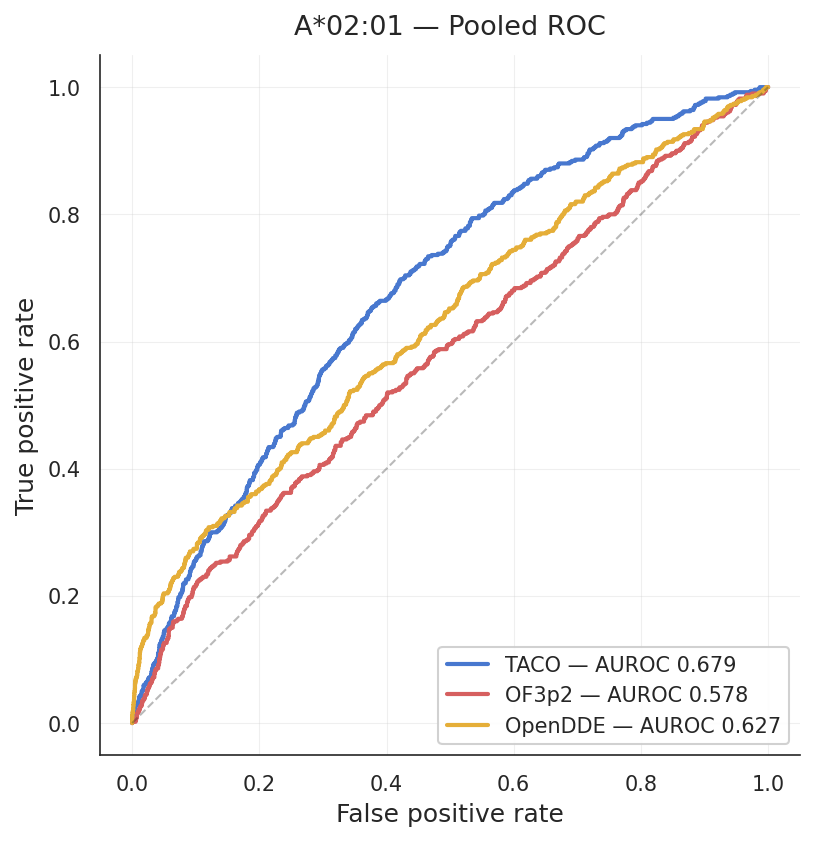


B*40:01
                           AUROC   AUC0.1     AUROC   AUC0.1
                        --- per-peptide mean ---    --- pooled ---  
  TACO                    0.5230   0.5131    0.5251   0.4975
  OF3p2                   0.5367   0.5142    0.5377   0.5143
  per-pep AUROC bootstrap 95% CI:
    TACO                 [0.4527, 0.5801]
    OF3p2                [0.4692, 0.5949]
  per-pep AUROC bootstrap delta (TACO-OF3p2) 95% CI: [-0.0662, 0.0354]


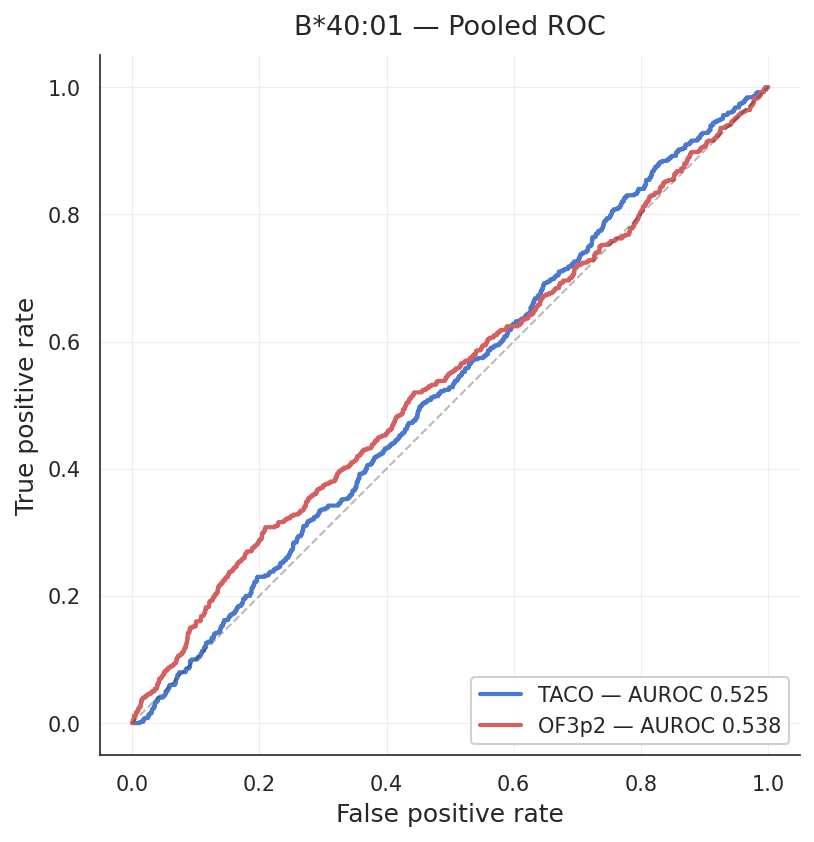

In [11]:
# --- TACO vs OF3p2 vs OpenDDE: AUROC and AUC0.1 ---
for allele, df_allele in [("A*02:01", df_A0201), ("B*40:01", df_B4001)]:
    peps = df_allele["peptide"].values
    labels = df_allele["label"].values
    taco_raw = df_allele["taco_score"].values
    of3p2 = df_allele["of3p2"].values.astype(float)
    has_dde = "opendde" in df_allele.columns and df_allele["opendde"].notna().any()

    models = {"TACO": taco_raw, "OF3p2": of3p2}
    if has_dde:
        models["OpenDDE"] = df_allele["opendde"].values.astype(float)

    print(f"\n{allele}")
    print(f"  {'':20s}  {'AUROC':>8s} {'AUC0.1':>8s}  {'AUROC':>8s} {'AUC0.1':>8s}")
    print(f"  {'':20s}  {'--- per-peptide mean ---':^18s}  {'--- pooled ---':^18s}")

    roc_data = {}
    for mname, scores in models.items():
        auroc_m, _ = per_peptide_auroc(peps, scores, labels)
        auc01_m, _ = per_peptide_partial_auroc(peps, scores, labels, max_fpr=0.1)
        pooled_auroc_m = pooled_auroc(scores, labels)
        pooled_auc01_m = _partial_auc(scores, labels, max_fpr=0.1)
        print(
            f"  {mname:<20s}  {auroc_m:>8.4f} {auc01_m:>8.4f}  {pooled_auroc_m:>8.4f} {pooled_auc01_m:>8.4f}"
        )
        roc_data[mname] = (pooled_auroc_m, *_roc_curve(scores, labels))

    # Standalone bootstrap 95% CIs (per-peptide mean AUROC)
    print(f"  per-pep AUROC bootstrap 95% CI:")
    for mname, scores in models.items():
        _, lo, hi, _ = peptide_bootstrap(peps, scores, labels)
        print(f"    {mname:<20s} [{lo:.4f}, {hi:.4f}]")

    # Paired bootstrap: TACO vs OF3p2
    _, lo_d, hi_d, _ = peptide_bootstrap_delta(peps, taco_raw, of3p2, labels)
    print(f"  per-pep AUROC bootstrap delta (TACO-OF3p2) 95% CI: [{lo_d:.4f}, {hi_d:.4f}]")
    if has_dde:
        _, lo_d2, hi_d2, _ = peptide_bootstrap_delta(peps, taco_raw, models["OpenDDE"], labels)
        print(f"  per-pep AUROC bootstrap delta (TACO-OpenDDE) 95% CI: [{lo_d2:.4f}, {hi_d2:.4f}]")

    # Pooled ROC curves
    _colors = {"TACO": "#4878CF", "OF3p2": "#D65F5F", "OpenDDE": "#E5AE38"}
    fig, ax = plt.subplots(figsize=(5.5, 5.5), constrained_layout=True)
    for mname, (pauc, fpr, tpr) in roc_data.items():
        ax.plot(fpr, tpr, label=f"{mname} — AUROC {pauc:.3f}", color=_colors[mname], linewidth=2)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1)
    ax.set_xlabel("False positive rate", fontsize=12)
    ax.set_ylabel("True positive rate", fontsize=12)
    ax.set_title(f"{allele} — Pooled ROC", fontsize=13, pad=10)
    ax.legend(loc="lower right", fontsize=10)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    plt.show()

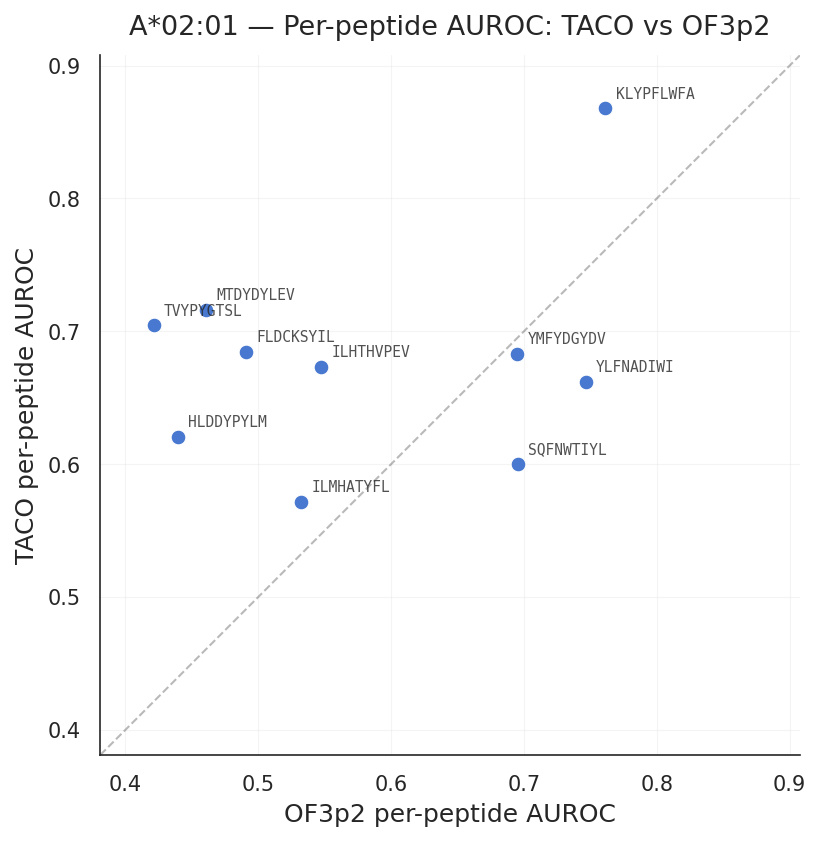

vs OF3p2: TACO wins 7/10 peptides, OF3p2 wins 3/10, ties 0


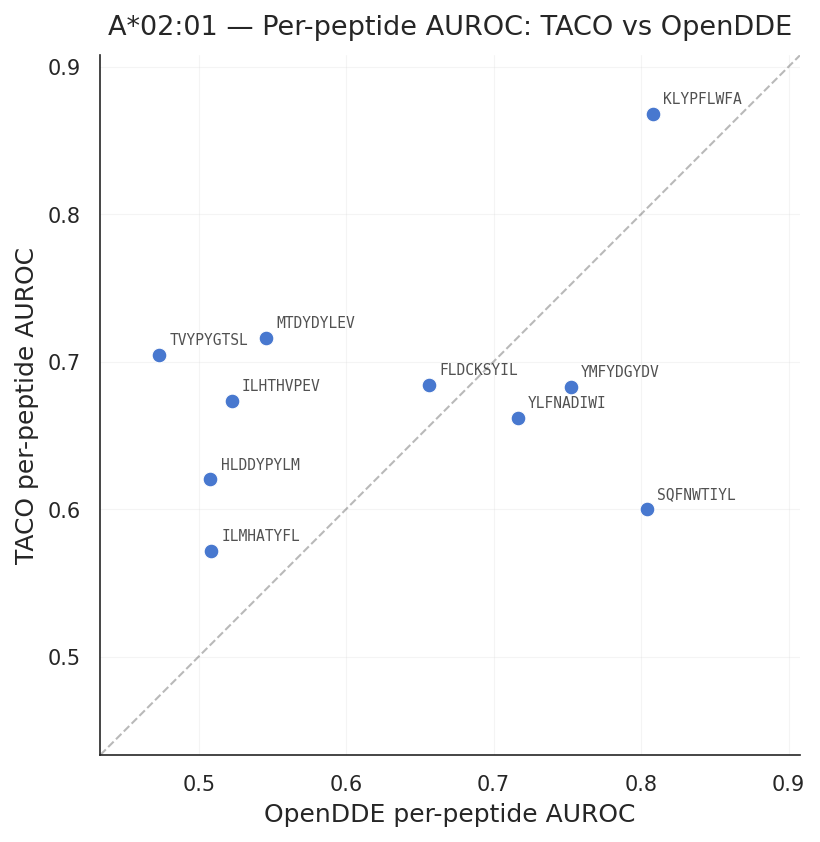

vs OpenDDE: TACO wins 7/10 peptides, OpenDDE wins 3/10, ties 0


In [12]:
# --- Scatter: per-peptide AUROC, TACO vs structure models, A*02:01 ---
peps_a = df_A0201["peptide"].values
labels_a = df_A0201["label"].values
unique_peps = np.unique(peps_a)

of3p2_vals = df_A0201["of3p2"].values.astype(float)
has_dde = "opendde" in df_A0201.columns and df_A0201["opendde"].notna().any()
dde_vals = df_A0201["opendde"].values.astype(float) if has_dde else None

comparisons = [("OF3p2", of3p2_vals)]
if has_dde:
    comparisons.append(("OpenDDE", dde_vals))

for comp_name, comp_scores in comparisons:
    taco_pp, comp_pp, pep_labels = [], [], []
    for p in unique_peps:
        mask = peps_a == p
        y = labels_a[mask]
        if y.min() == y.max():
            continue
        s_taco = df_A0201["taco_score"].values[mask]
        s_comp = comp_scores[mask]
        r_t = rankdata(s_taco)
        r_c = rankdata(s_comp)
        n1, n0 = y.sum(), (1 - y).sum()
        taco_pp.append((r_t[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        comp_pp.append((r_c[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))
        pep_labels.append(p)

    taco_pp = np.array(taco_pp)
    comp_pp = np.array(comp_pp)

    fig, ax = plt.subplots(figsize=(5.5, 5.5), constrained_layout=True)
    ax.scatter(
        comp_pp, taco_pp, s=50, zorder=3, color="#4878CF", edgecolors="white", linewidth=0.5
    )

    try:
        from adjustText import adjust_text

        texts = [
            ax.text(comp_pp[i], taco_pp[i], p, fontsize=7, fontfamily="monospace", alpha=0.8)
            for i, p in enumerate(pep_labels)
        ]
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", alpha=0.4, lw=0.5))
    except ImportError:
        for i, p in enumerate(pep_labels):
            ax.annotate(
                p,
                (comp_pp[i], taco_pp[i]),
                fontsize=7,
                fontfamily="monospace",
                alpha=0.8,
                xytext=(5, 5),
                textcoords="offset points",
            )

    lo = min(comp_pp.min(), taco_pp.min()) - 0.04
    hi = max(comp_pp.max(), taco_pp.max()) + 0.04
    ax.plot([lo, hi], [lo, hi], "k--", alpha=0.3, linewidth=1)
    ax.set_xlabel(f"{comp_name} per-peptide AUROC", fontsize=12)
    ax.set_ylabel("TACO per-peptide AUROC", fontsize=12)
    ax.set_title(f"A*02:01 — Per-peptide AUROC: TACO vs {comp_name}", fontsize=13, pad=10)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)
    plt.show()

    n_taco_wins = (taco_pp > comp_pp).sum()
    n_comp_wins = (comp_pp > taco_pp).sum()
    n_tie = (taco_pp == comp_pp).sum()
    print(
        f"vs {comp_name}: TACO wins {n_taco_wins}/{len(taco_pp)} peptides, "
        f"{comp_name} wins {n_comp_wins}/{len(taco_pp)}, ties {n_tie}"
    )

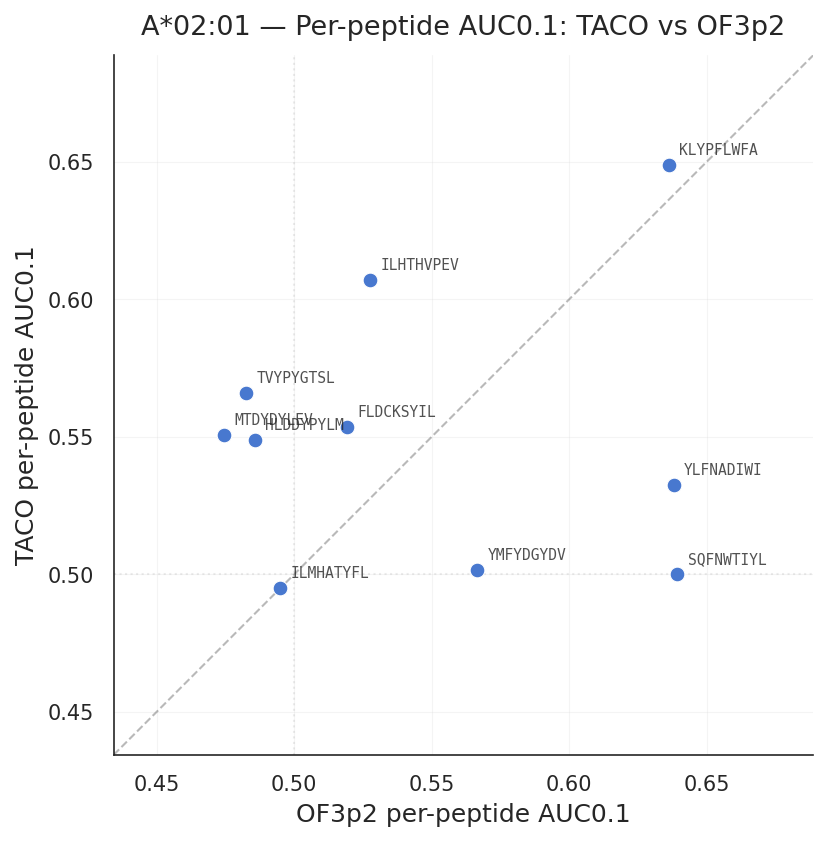

AUC0.1 vs OF3p2: TACO wins 6/10, OF3p2 wins 3/10


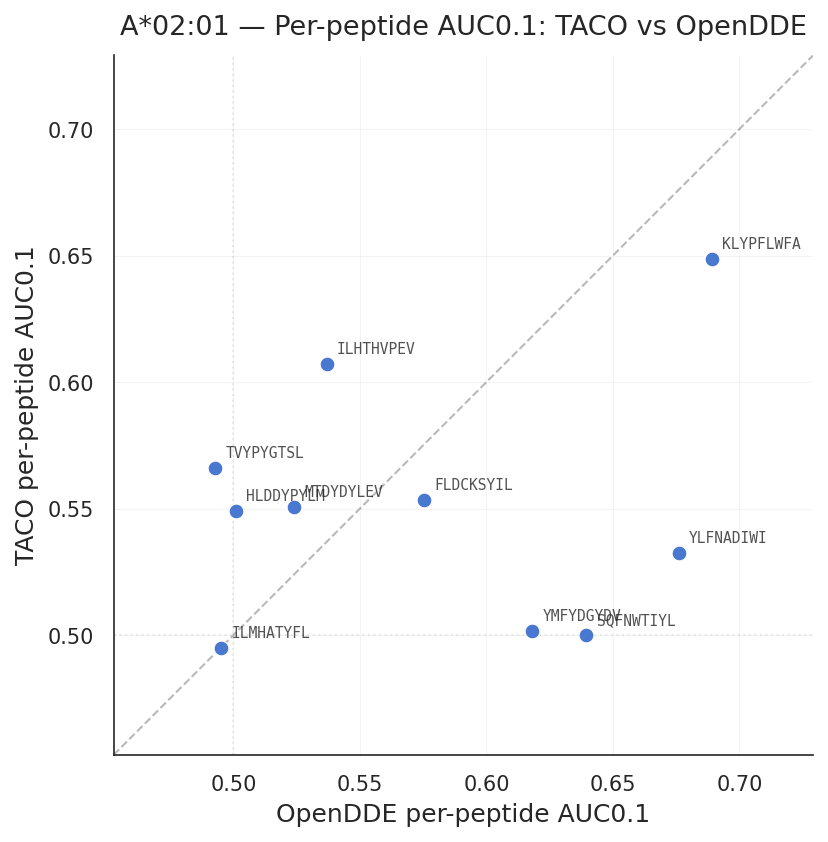

AUC0.1 vs OpenDDE: TACO wins 4/10, OpenDDE wins 6/10


In [13]:
# --- Scatter: per-peptide AUC0.1, TACO vs structure models, A*02:01 ---
peps_a = df_A0201["peptide"].values
labels_a = df_A0201["label"].values

_, taco_auc01_pp = per_peptide_partial_auroc(
    peps_a, df_A0201["taco_score"].values, labels_a, max_fpr=0.1
)
_, of3p2_auc01_pp = per_peptide_partial_auroc(
    peps_a, df_A0201["of3p2"].values.astype(float), labels_a, max_fpr=0.1
)

has_dde = "opendde" in df_A0201.columns and df_A0201["opendde"].notna().any()
comparisons = [("OF3p2", of3p2_auc01_pp)]
if has_dde:
    _, dde_auc01_pp = per_peptide_partial_auroc(
        peps_a, df_A0201["opendde"].values.astype(float), labels_a, max_fpr=0.1
    )
    comparisons.append(("OpenDDE", dde_auc01_pp))

unique_peps = np.unique(peps_a)
pep_labels = [p for p in unique_peps if labels_a[peps_a == p].min() != labels_a[peps_a == p].max()]

for comp_name, comp_auc01 in comparisons:
    fig, ax = plt.subplots(figsize=(5.5, 5.5), constrained_layout=True)
    ax.scatter(
        comp_auc01,
        taco_auc01_pp,
        s=50,
        zorder=3,
        color="#4878CF",
        edgecolors="white",
        linewidth=0.5,
    )

    try:
        from adjustText import adjust_text

        texts = [
            ax.text(
                comp_auc01[i], taco_auc01_pp[i], p, fontsize=7, fontfamily="monospace", alpha=0.8
            )
            for i, p in enumerate(pep_labels)
        ]
        adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", alpha=0.4, lw=0.5))
    except ImportError:
        for i, p in enumerate(pep_labels):
            ax.annotate(
                p,
                (comp_auc01[i], taco_auc01_pp[i]),
                fontsize=7,
                fontfamily="monospace",
                alpha=0.8,
                xytext=(5, 5),
                textcoords="offset points",
            )

    lo = min(comp_auc01.min(), taco_auc01_pp.min()) - 0.04
    hi = max(comp_auc01.max(), taco_auc01_pp.max()) + 0.04
    ax.plot([lo, hi], [lo, hi], "k--", alpha=0.3, linewidth=1)
    ax.axhline(0.5, color="gray", alpha=0.15, linewidth=1, linestyle=":")
    ax.axvline(0.5, color="gray", alpha=0.15, linewidth=1, linestyle=":")
    ax.set_xlabel(f"{comp_name} per-peptide AUC0.1", fontsize=12)
    ax.set_ylabel("TACO per-peptide AUC0.1", fontsize=12)
    ax.set_title(f"A*02:01 — Per-peptide AUC0.1: TACO vs {comp_name}", fontsize=13, pad=10)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)
    plt.show()

    n_taco_wins = (taco_auc01_pp > comp_auc01).sum()
    n_comp_wins = (comp_auc01 > taco_auc01_pp).sum()
    print(
        f"AUC0.1 vs {comp_name}: TACO wins {n_taco_wins}/{len(taco_auc01_pp)}, "
        f"{comp_name} wins {n_comp_wins}/{len(taco_auc01_pp)}"
    )

### Ensembles: TACO + structure models

Per-peptide z-score each model independently, then average.  Z-scoring puts models
on a common mean-0, std-1 scale within each peptide, so averaging gives equal weight.

Ensembles tested:
- **TACO + OF3p2** (both alleles)
- **TACO + OpenDDE** (A\*02:01 only)
- **OF3p2 + OpenDDE** (A\*02:01 only)
- **TACO + OF3p2 + OpenDDE** (A\*02:01 only)


A*02:01
                                AUROC   AUC0.1     AUROC   AUC0.1
                             --- per-peptide mean ---    --- pooled ---  
  TACO                         0.6782   0.5504    0.6789   0.5444
  OF3p2                        0.5789   0.5464    0.5778   0.5325
  OpenDDE                      0.6294   0.5747    0.6275   0.5725
  TACO + OF3p2                 0.6628   0.5690    0.6627   0.5617
  TACO + OpenDDE               0.6902   0.5714    0.6901   0.5653
  OF3p2 + OpenDDE              0.6149   0.5681    0.6140   0.5574
  TACO + OF3p2 + OpenDDE       0.6684   0.5805    0.6690   0.5718


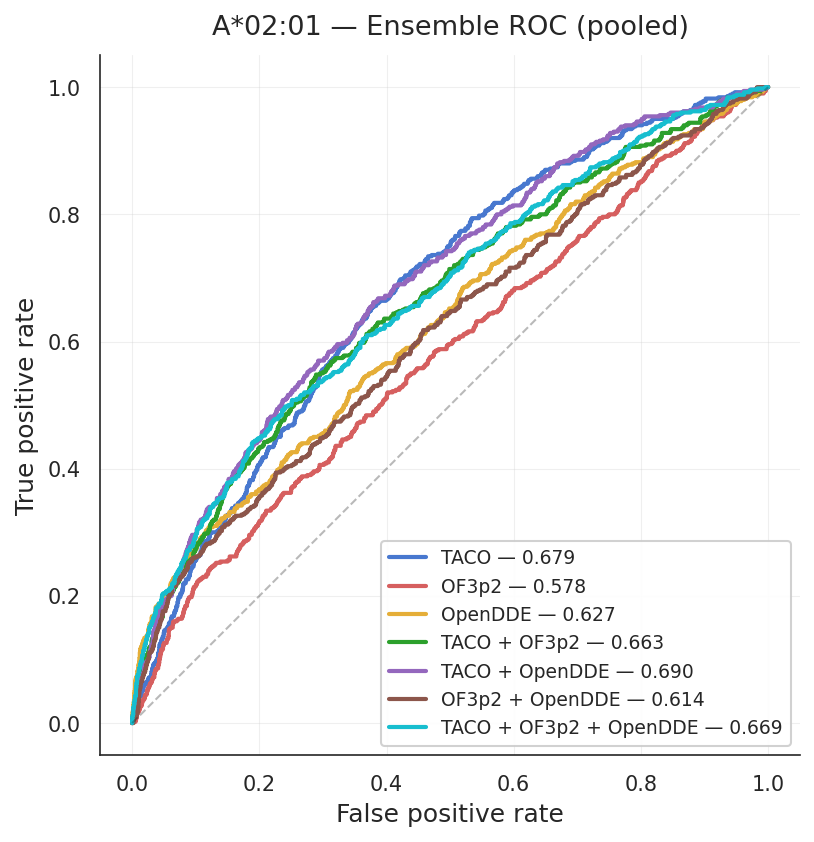

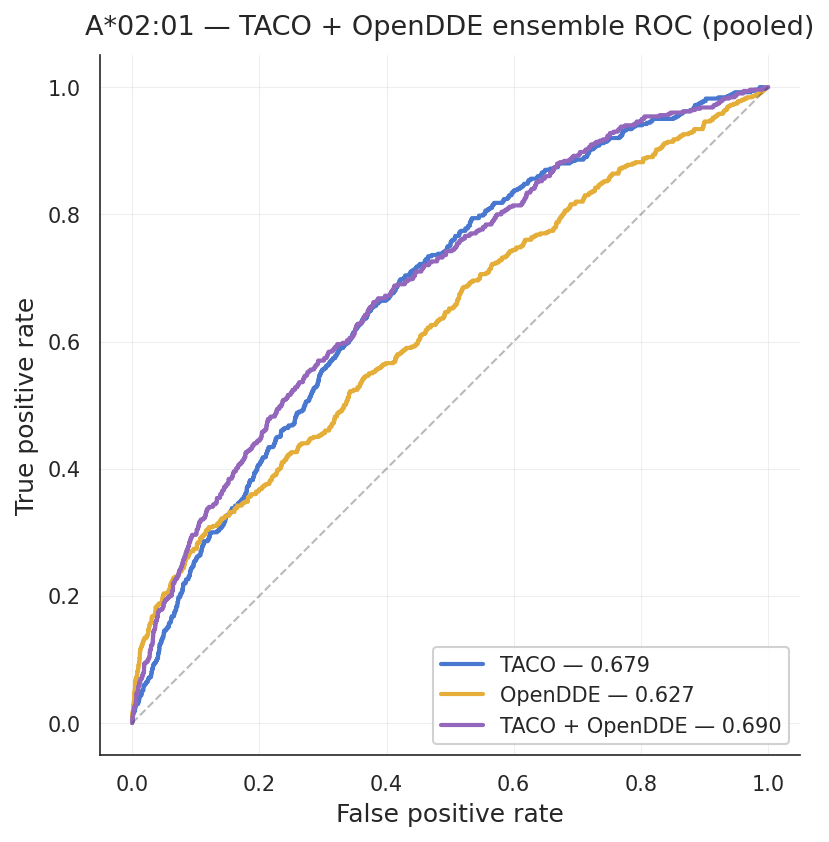


B*40:01
                                AUROC   AUC0.1     AUROC   AUC0.1
                             --- per-peptide mean ---    --- pooled ---  
  TACO                         0.5230   0.5131    0.5251   0.4975
  OF3p2                        0.5367   0.5142    0.5377   0.5143
  TACO + OF3p2                 0.5360   0.5192    0.5389   0.5172


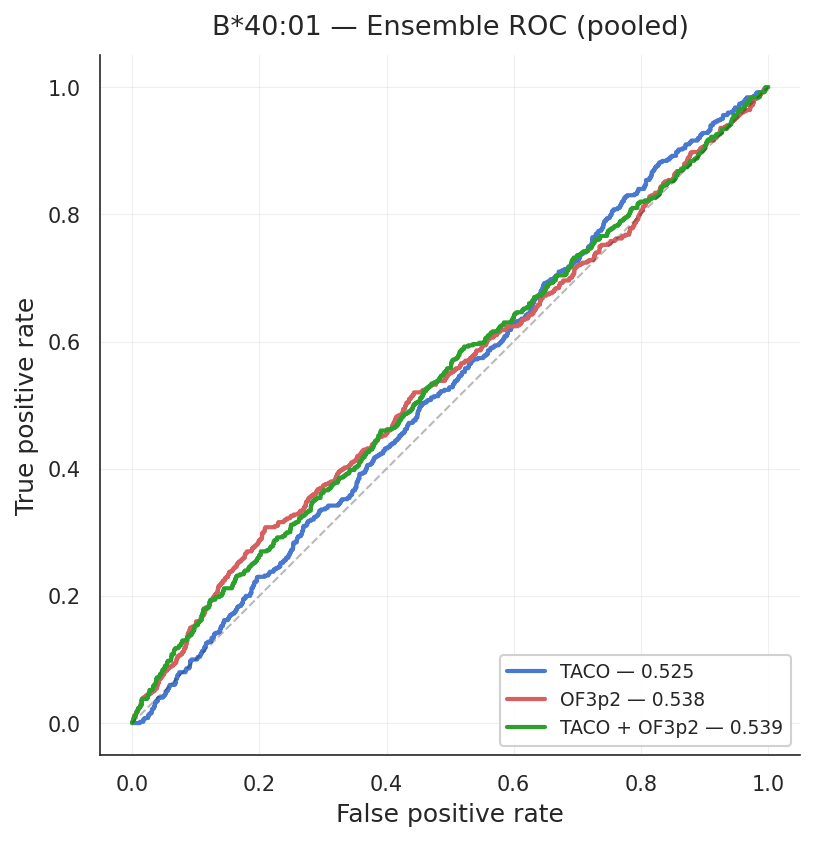

In [14]:
def _per_peptide_zscore(peptides, scores):
    """Z-score scores within each peptide group. Returns array same shape as scores."""
    out = np.empty_like(scores, dtype=float)
    for p in np.unique(peptides):
        mask = peptides == p
        s = scores[mask].astype(float)
        mu, sigma = s.mean(), s.std()
        if sigma == 0:
            sigma = 1.0
        out[mask] = (s - mu) / sigma
    return out


_ens_colors = {
    "TACO": "#4878CF",
    "OF3p2": "#D65F5F",
    "OpenDDE": "#E5AE38",
    "TACO + OF3p2": "#2CA02C",
    "TACO + OpenDDE": "#9467BD",
    "OF3p2 + OpenDDE": "#8C564B",
    "TACO + OF3p2 + OpenDDE": "#17BECF",
}

for allele, df_allele in [("A*02:01", df_A0201), ("B*40:01", df_B4001)]:
    peps = df_allele["peptide"].values
    labels = df_allele["label"].values
    taco_raw = df_allele["taco_score"].values
    of3p2_raw = df_allele["of3p2"].values.astype(float)
    has_dde = "opendde" in df_allele.columns and df_allele["opendde"].notna().any()

    taco_pz = _per_peptide_zscore(peps, taco_raw)
    of3p2_pz = _per_peptide_zscore(peps, of3p2_raw)

    models = {"TACO": taco_raw, "OF3p2": of3p2_raw}
    ensembles = {"TACO + OF3p2": (taco_pz + of3p2_pz) / 2.0}

    if has_dde:
        dde_raw = df_allele["opendde"].values.astype(float)
        dde_pz = _per_peptide_zscore(peps, dde_raw)
        models["OpenDDE"] = dde_raw
        ensembles["TACO + OpenDDE"] = (taco_pz + dde_pz) / 2.0
        ensembles["OF3p2 + OpenDDE"] = (of3p2_pz + dde_pz) / 2.0
        ensembles["TACO + OF3p2 + OpenDDE"] = (taco_pz + of3p2_pz + dde_pz) / 3.0

    all_models = {**models, **ensembles}

    print(f"\n{allele}")
    print(f"  {'':25s}  {'AUROC':>8s} {'AUC0.1':>8s}  {'AUROC':>8s} {'AUC0.1':>8s}")
    print(f"  {'':25s}  {'--- per-peptide mean ---':^18s}  {'--- pooled ---':^18s}")

    roc_data = {}
    for mname, scores in all_models.items():
        auroc_m, _ = per_peptide_auroc(peps, scores, labels)
        auc01_m, _ = per_peptide_partial_auroc(peps, scores, labels, max_fpr=0.1)
        pooled_auroc_m = pooled_auroc(scores, labels)
        pooled_auc01_m = _partial_auc(scores, labels, max_fpr=0.1)
        print(
            f"  {mname:<25s}  {auroc_m:>8.4f} {auc01_m:>8.4f}  {pooled_auroc_m:>8.4f} {pooled_auc01_m:>8.4f}"
        )
        roc_data[mname] = (pooled_auroc_m, *_roc_curve(scores, labels))

    # ROC curves
    fig, ax = plt.subplots(figsize=(6, 5.5), constrained_layout=True)
    for mname, (pauc, fpr, tpr) in roc_data.items():
        ax.plot(fpr, tpr, label=f"{mname} — {pauc:.3f}", color=_ens_colors[mname], linewidth=2)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1)
    ax.set_xlabel("False positive rate", fontsize=12)
    ax.set_ylabel("True positive rate", fontsize=12)
    ax.set_title(f"{allele} — Ensemble ROC (pooled)", fontsize=13, pad=10)
    ax.legend(loc="lower right", fontsize=9)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    plt.show()

    # Focused ROC: only TACO, OpenDDE, Ens(TACO, OpenDDE)
    if has_dde:
        _focus = ["TACO", "OpenDDE", "TACO + OpenDDE"]
        fig, ax = plt.subplots(figsize=(6, 5.5), constrained_layout=True)
        for mname in _focus:
            pauc, fpr, tpr = roc_data[mname]
            ax.plot(fpr, tpr, label=f"{mname} — {pauc:.3f}", color=_ens_colors[mname], linewidth=2)
        ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1)
        ax.set_xlabel("False positive rate", fontsize=12)
        ax.set_ylabel("True positive rate", fontsize=12)
        ax.set_title(f"{allele} — TACO + OpenDDE ensemble ROC (pooled)", fontsize=13, pad=10)
        ax.legend(loc="lower right", fontsize=10)
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.3)
        plt.show()


A*02:01  (10 peptides)
  Ens(TACO, OpenDDE) vs TACO alone
  mean AUROC delta = +0.0105   95% CI [-0.0389, +0.0580]


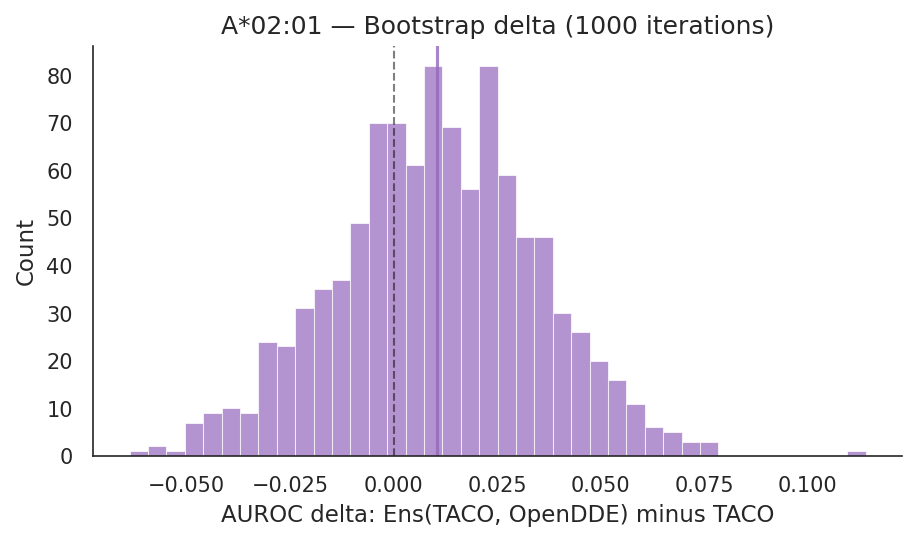


B*40:01: OpenDDE not available, skipping


In [15]:
# --- Bootstrap delta: Ens(TACO, OpenDDE) vs TACO alone ---
for allele, df_allele in [("A*02:01", df_A0201), ("B*40:01", df_B4001)]:
    has_dde = "opendde" in df_allele.columns and df_allele["opendde"].notna().any()
    if not has_dde:
        print(f"\n{allele}: OpenDDE not available, skipping")
        continue

    peps = df_allele["peptide"].values
    labels = df_allele["label"].values
    taco_raw = df_allele["taco_score"].values
    dde_raw = df_allele["opendde"].values.astype(float)

    taco_pz = _per_peptide_zscore(peps, taco_raw)
    dde_pz = _per_peptide_zscore(peps, dde_raw)
    ens = (taco_pz + dde_pz) / 2.0

    mu, lo, hi, deltas = peptide_bootstrap_delta(peps, ens, taco_raw, labels)
    n_peps = len(np.unique(peps))

    print(f"\n{allele}  ({n_peps} peptides)")
    print(f"  Ens(TACO, OpenDDE) vs TACO alone")
    print(f"  mean AUROC delta = {mu:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]")

    fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
    ax.hist(deltas, bins=40, alpha=0.7, color="#9467BD", edgecolor="white", linewidth=0.5)
    ax.axvline(0, color="black", lw=1, ls="--", alpha=0.5)
    ax.axvline(mu, color="#9467BD", lw=1.5, ls="-", alpha=0.8)
    ax.set_xlabel("AUROC delta: Ens(TACO, OpenDDE) minus TACO", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title(f"{allele} — Bootstrap delta ({len(deltas)} iterations)", fontsize=12)
    plt.show()

### Beta-only scoring

How much signal comes from TCR-beta alone?  To test this we exclude the alpha loop
contributions from the contact geometry entirely — `score_beta` sums only beta-chain
loops, so any discrimination comes exclusively from the beta CDRs.


Per-peptide AUROC with beta-only vs full TCR quantifies the alpha chain's contribution.


In [16]:
# --- Beta-only via score_beta ---
for allele, df_allele in [("A*02:01", df_A0201), ("B*40:01", df_B4001)]:
    scores_beta = TACO.score_beta(df_allele)

    peps = df_allele["peptide"].values
    labels = df_allele["label"].values

    # Full model
    auroc_full, _ = per_peptide_auroc(peps, df_allele["taco_score"].values, labels)
    pooled_full = pooled_auroc(df_allele["taco_score"].values, labels)

    # Beta-only
    auroc_beta, _ = per_peptide_auroc(peps, scores_beta, labels)
    pooled_beta = pooled_auroc(scores_beta, labels)

    # Bootstrap CIs
    _, lo_full, hi_full, _ = peptide_bootstrap(peps, df_allele["taco_score"].values, labels)
    _, lo_beta, hi_beta, _ = peptide_bootstrap(peps, scores_beta, labels)

    # Paired bootstrap on per-peptide delta (full - beta)
    _, lo_delta, hi_delta, _ = peptide_bootstrap_delta(
        peps, df_allele["taco_score"].values, scores_beta, labels
    )

    print(f"\n{allele}")
    print(f"  {'':24s}  {'per-pep AUROC':>14s}  {'pooled AUROC':>14s}")
    print(
        f"  {'full TCR (α+β)':<24s}  {auroc_full:>14.4f}  {pooled_full:>14.4f}   95% CI [{lo_full:.4f}, {hi_full:.4f}]"
    )
    print(
        f"  {'beta-only':<24s}  {auroc_beta:>14.4f}  {pooled_beta:>14.4f}   95% CI [{lo_beta:.4f}, {hi_beta:.4f}]"
    )
    print(
        f"  {'delta (full−beta)':<24s}  {auroc_full - auroc_beta:>+14.4f}  {pooled_full - pooled_beta:>+14.4f}   95% CI [{lo_delta:.4f}, {hi_delta:.4f}]"
    )


A*02:01
                             per-pep AUROC    pooled AUROC
  full TCR (α+β)                    0.6782          0.6789   95% CI [0.6302, 0.7352]
  beta-only                         0.6536          0.6514   95% CI [0.6066, 0.6979]
  delta (full−beta)                +0.0246         +0.0275   95% CI [-0.0132, 0.0696]

B*40:01
                             per-pep AUROC    pooled AUROC
  full TCR (α+β)                    0.5230          0.5251   95% CI [0.4527, 0.5801]
  beta-only                         0.5194          0.5273   95% CI [0.4516, 0.5831]
  delta (full−beta)                +0.0036         -0.0022   95% CI [-0.0508, 0.0592]


---

## Inference speed

Benchmark on synthetic TCRs with realistic CDR lengths (medians from IMMREP A\*02:01)
and random amino-acid sequences drawn from the model's alphabet.

Four scenarios at two scales (10K and 1M distinct TCRs), each with 1 or 100 peptides:
- **10K TCRs x 1 peptide** — baseline single-peptide cost.
- **10K TCRs x 100 peptides** — geometry is computed once per peptide length and reused
  across all peptides of that length, so adding peptides is cheap.
- **1M TCRs x 1 peptide** — scaling test for large repertoires.
- **1M TCRs x 100 peptides** — uses panel mode (`score(df_tcr, peptides=...)`) which avoids
  building a 100M-row cross-product DataFrame.  Geometry stays contiguous in memory and is
  reused across peptides.

Each scenario is run single-threaded and with multiprocessing to show where parallelization
helps and where the overhead exceeds the gain.  Parallelization distributes peptide scoring
across workers (geometry computed once in the parent, shared via fork), so it helps most
when there are many peptides and enough TCRs to amortize the fork overhead.

In [16]:
# --- Build synthetic dataset from IMMREP statistics ---
rng = np.random.default_rng(0)
alphabet = list(TACO.spec["alphabet"])

cdr_cols = ["cdr1a", "cdr2a", "cdr3a", "cdr1b", "cdr2b", "cdr3b"]
median_lens = {c: int(df_A0201[c].str.len().median()) for c in cdr_cols}
print("Median CDR lengths (from A*02:01):")
for c, l in median_lens.items():
    print(f"  {c}: {l}")

N_TCR_10K = 10_000
N_TCR_1M = 1_000_000
N_PEP = 100
PEP_LEN = 9


def random_seqs(n, length, rng):
    return ["".join(rng.choice(alphabet, size=length)) for _ in range(n)]


# 10K distinct TCRs
synth_tcrs_10k = {c: random_seqs(N_TCR_10K, median_lens[c], rng) for c in cdr_cols}

# 1M distinct TCRs
print(f"\nGenerating {N_TCR_1M:,} distinct synthetic TCRs...")
t0 = time.time()
synth_tcrs_1m = {c: random_seqs(N_TCR_1M, median_lens[c], rng) for c in cdr_cols}
print(f"  done in {time.time() - t0:.1f}s")

# Peptides: real 9-mers from the data, padded with random ones
real_9mers = df_A0201[df_A0201.peptide.str.len() == PEP_LEN].peptide.unique()
pep_1 = [real_9mers[0]]
pep_100 = list(real_9mers[: min(len(real_9mers), N_PEP)])
while len(pep_100) < N_PEP:
    pep_100.append("".join(rng.choice(alphabet, size=PEP_LEN)))
pep_100 = list(dict.fromkeys(pep_100))

# --- 10K-TCR DataFrames (with peptide column, for score(df) path) ---
df_1pep = pd.DataFrame(synth_tcrs_10k)
df_1pep["peptide"] = pep_1[0]

df_100pep = pd.concat(
    [pd.DataFrame({**{c: synth_tcrs_10k[c] for c in cdr_cols}, "peptide": p}) for p in pep_100],
    ignore_index=True,
)

# --- 1M-TCR DataFrames ---
df_1M_1pep = pd.DataFrame(synth_tcrs_1m)
df_1M_1pep["peptide"] = pep_1[0]

# For 1M x 100 peptides we use score(df_tcr, peptides=...) panel mode
# instead of building a 100M-row cross-product DataFrame
df_1M_tcrs = pd.DataFrame(synth_tcrs_1m)  # TCR-only, no peptide column

print(f"\n{'DataFrame':<16s}  {'Rows':>14s}  {'TCRs':>10s}  {'Peptides':>10s}  {'Mode':>10s}")
print("-" * 66)
for name, n_rows, nt, np_, mode in [
    ("df_1pep", len(df_1pep), N_TCR_10K, 1, "score(df)"),
    ("df_100pep", len(df_100pep), N_TCR_10K, N_PEP, "score(df)"),
    ("df_1M_1pep", len(df_1M_1pep), N_TCR_1M, 1, "score(df)"),
    ("df_1M_tcrs", len(df_1M_tcrs), N_TCR_1M, N_PEP, "panel"),
]:
    print(f"{name:<16s}  {n_rows:>14,}  {nt:>10,}  {np_:>10,}  {mode:>10s}")

Median CDR lengths (from A*02:01):
  cdr1a: 6
  cdr2a: 7
  cdr3a: 13
  cdr1b: 5
  cdr2b: 6
  cdr3b: 14

Generating 1,000,000 distinct synthetic TCRs...
  done in 90.4s

DataFrame                   Rows        TCRs    Peptides        Mode
------------------------------------------------------------------
df_1pep                   10,000      10,000           1   score(df)
df_100pep              1,000,000      10,000         100   score(df)
df_1M_1pep             1,000,000   1,000,000           1   score(df)
df_1M_tcrs             1,000,000   1,000,000         100       panel


In [17]:
import multiprocessing

n_cores = multiprocessing.cpu_count()
print(f"Cores: {n_cores} logical\n")

# --- Scenarios using score(df) — DataFrame with peptide column ---
df_scenarios = [
    ("10K TCRs x 1 pep", df_1pep),
    ("10K TCRs x 100 pep", df_100pep),
    ("1M TCRs x 1 pep", df_1M_1pep),
]

results = []
for label, df_bench in df_scenarios:
    n = len(df_bench)
    print(f"▸ {label}  ({n:,} rows)", flush=True)

    t0 = time.time()
    s1 = TACO.score(df_bench, parallel=False)
    t_single = time.time() - t0

    t0 = time.time()
    s2 = TACO.score(df_bench, parallel=True)
    t_parallel = time.time() - t0

    max_diff = np.max(np.abs(s1 - s2))
    tag = "exact" if max_diff == 0 else f"{max_diff:.0e}" if max_diff < 1e-6 else "MISMATCH"
    speedup = t_single / t_parallel

    print(f"  single: {t_single:>8.2f}s  ({n / t_single:>12,.0f} pred/s)")
    print(
        f"  multi:  {t_parallel:>8.2f}s  ({n / t_parallel:>12,.0f} pred/s)  {speedup:.1f}x  match={tag}"
    )
    print(flush=True)

    results.append((label, n, t_single, t_parallel, max_diff))

# --- 1M TCRs x 100 peptides via panel mode (no 100M-row DataFrame) ---
label = "1M TCRs x 100 pep"
n = N_TCR_1M * len(pep_100)
print(f"▸ {label}  ({n:,} evaluations, panel mode)", flush=True)

t0 = time.time()
p1 = TACO.score(df_1M_tcrs, peptides=pep_100, parallel=False)
t_single = time.time() - t0

t0 = time.time()
p2 = TACO.score(df_1M_tcrs, peptides=pep_100, parallel=True)
t_parallel = time.time() - t0

max_diff = np.max(np.abs(p1.values - p2.values))
tag = "exact" if max_diff == 0 else f"{max_diff:.0e}" if max_diff < 1e-6 else "MISMATCH"
speedup = t_single / t_parallel

print(f"  single: {t_single:>8.2f}s  ({n / t_single:>12,.0f} pred/s)")
print(
    f"  multi:  {t_parallel:>8.2f}s  ({n / t_parallel:>12,.0f} pred/s)  {speedup:.1f}x  match={tag}"
)
print(flush=True)

results.append((label, n, t_single, t_parallel, max_diff))

# Summary table
print("=" * 108)
print("SUMMARY")
print("=" * 108)
hdr = (
    f"{'Scenario':<22s}  {'Evaluations':>14s}  "
    f"{'Single':>8s}  {'pred/s':>12s}  "
    f"{'Multi':>8s}  {'pred/s':>12s}  "
    f"{'Speedup':>8s}  {'Match':>8s}"
)
print(hdr)
print("-" * len(hdr))
for label, n, ts, tp, md in results:
    tag = "exact" if md == 0 else f"{md:.0e}" if md < 1e-6 else "MISMATCH"
    print(
        f"{label:<22s}  {n:>14,}  "
        f"{ts:>7.2f}s  {n / ts:>12,.0f}  "
        f"{tp:>7.2f}s  {n / tp:>12,.0f}  "
        f"{ts / tp:>7.1f}x  {tag:>8s}"
    )

Cores: 64 logical

▸ 10K TCRs x 1 pep  (10,000 rows)
  single:     0.31s  (      31,951 pred/s)
  multi:      1.61s  (       6,224 pred/s)  0.2x  match=exact

▸ 10K TCRs x 100 pep  (1,000,000 rows)
  single:     8.71s  (     114,839 pred/s)
  multi:      9.16s  (     109,182 pred/s)  1.0x  match=exact

▸ 1M TCRs x 1 pep  (1,000,000 rows)
  single:    55.67s  (      17,964 pred/s)
  multi:     26.53s  (      37,692 pred/s)  2.1x  match=exact

▸ 1M TCRs x 100 pep  (100,000,000 evaluations, panel mode)
  single:   414.48s  (     241,267 pred/s)
  multi:    246.21s  (     406,159 pred/s)  1.7x  match=exact

SUMMARY
Scenario                   Evaluations    Single        pred/s     Multi        pred/s   Speedup     Match
----------------------------------------------------------------------------------------------------------
10K TCRs x 1 pep                10,000     0.31s        31,951     1.61s         6,224      0.2x     exact
10K TCRs x 100 pep           1,000,000     8.71s       114,8